# Team 19 - Overhead-Conductor Data Pipeline

**Single-notebook interface for the SA Power Networks release handover**

The notebook orchestrates independently testable Python modules in `src/`. It **does not reimplement** ingestion, validation, cleaning, imputation or evaluation: every cell below calls the same stage functions as the `oc-pipeline` command line (`src.pipeline.run_*`), so a run from this notebook and a run from the terminal produce the same files.

Sections: 0 configuration · 1 ingestion · 2 validation · 3 exploratory analysis · 4 preprocessing and deterministic recovery · 5 imputation method · 6 postprocessing and provenance · 7 evaluation and diagnostics · 8 export and report.

> Every file under `data/overhead_conductors/` is **synthetic**; no SA Power Networks operational data is read, written or quoted here. Results on synthetic data demonstrate that the pipeline runs end to end and show how the methods behave on a generated population; they do **not** establish performance on real SAPN records. Domain rules that need a SAPN decision (for example the `code_mappings` cleaning family) are shipped **unapproved** and skipped until a domain owner approves them.

## ⚙️ Project Configuration and Dataset Selection

This section defines the configuration, dataset, and output paths for the **Overhead Conductor Data Quality and Imputation Pipeline**, developed as part of the University of Adelaide Capstone Project in collaboration with SA Power Networks.

All paths are managed centrally to simplify dataset selection, configuration changes, and experimental execution.

### 0.1 Asset Class

**Selected Asset:** `overhead_conductors`

The pipeline processes synthetic overhead-conductor asset records using asset-specific schemas, cleaning rules, and imputation configurations.

### 0.2 Dataset Selection

**Selected Scenario:** `synthetic_masked`

The experiment uses two input datasets:

| Dataset | Filename | Purpose |
|---------|----------|---------|
| Measured Data | `conductors_synthetic_masked.csv` | Contains missing values that require imputation |
| Ground Truth | `conductors_synthetic_complete.csv` | Contains the corresponding complete reference values for evaluation |

The ground-truth dataset is used exclusively for evaluating imputation performance and is not provided to the imputation model during training.

### 0.3 Asset Configuration

The following configuration files are loaded from `config/overhead_conductors/`:

| Configuration File | Responsibility |
|-------------------|----------------|
| `data_schema.yaml` | Defines attributes, data types, categorical values, constraints, and predictor roles |
| `cleaning_rules.yaml` | Specifies data cleaning, standardisation, and validation rules |
| `imputation.yaml` | Defines imputation attributes, method parameters, and model configurations |
| `pipeline.yaml` | Controls pipeline execution, validation, and evaluation settings |

### 0.4 Imputation Attributes

The overhead-conductor dataset contains seven model attributes:

**Numerical Attributes**
- `installation_year`
- `distance_to_sea_km`

**Categorical Attributes**
- `voltage_category`
- `location_group`
- `corrosion_zone`
- `material`
- `covering`

These attributes are used for missing-value imputation according to the selected method and asset configuration.

### 0.5 Experimental Output

The pipeline saves results in a scenario-specific directory:

`outputs/overhead_conductors/synthetic_masked/`

Generated outputs include:

- Data quality and profiling results
- Cleaned and preprocessed datasets
- Imputed datasets
- Imputation diagnostics and provenance
- Validation results
- Ground-truth evaluation metrics
- Visualisations and HTML reports

Keeping outputs separate for each scenario supports reproducibility and comparison between imputation methods.

### 0.6 Execution Instructions

Before executing the notebook:

1. Verify that `ASSET` is set to `overhead_conductors`.
2. Select the appropriate measured and ground-truth datasets.
3. Confirm that the configuration files exist.
4. Review the output directory.
5. Run the configuration cell before executing the remaining pipeline stages.

> **Important:** Changes to datasets, configuration paths, or output locations should be made in the Project Configuration cell below. The remaining notebook cells use these settings automatically.

> **Research Note:** The included dataset is synthetic. Imputation performance on synthetic data does not establish performance on real SA Power Networks asset records.

In [1]:
# ============================================================
# PROJECT CONFIGURATION
# ============================================================

from pathlib import Path
import os

# Automatically locate the project root
CURRENT_DIR = Path.cwd().resolve()

PROJECT_ROOT = next(
    (
        path for path in (CURRENT_DIR, *CURRENT_DIR.parents)
        if (path / "src" / "__init__.py").is_file()
        and (path / "config").is_dir()
    ),
    None
)

if PROJECT_ROOT is None:
    raise RuntimeError("Could not locate the pipeline project root.")


# ---------------- ASSET CONFIGURATION ----------------

ASSET = "overhead_conductors"

CONFIG_DIR = PROJECT_ROOT / "config" / ASSET

PIPELINE_CONFIG = CONFIG_DIR / "pipeline.yaml"
DATA_SCHEMA_CONFIG = CONFIG_DIR / "data_schema.yaml"
CLEANING_CONFIG = CONFIG_DIR / "cleaning_rules.yaml"
IMPUTATION_CONFIG = CONFIG_DIR / "imputation.yaml"


# ---------------- DATASET CONFIGURATION ----------------

INPUT_FILE = "data/overhead_conductors/conductors_synthetic_masked.csv"

TRUTH_FILE = "data/overhead_conductors/conductors_synthetic_complete.csv"


# ---------------- OUTPUT CONFIGURATION ----------------

OUTPUT_DIR = "outputs/overhead_conductors/run_01"

# ---------------- DISPLAY CONFIGURATION ----------------

HOME_DIR = str(Path.home())

print("Project Root:", str(PROJECT_ROOT).replace(HOME_DIR, "~", 1))
print("Asset:", ASSET)
print("Pipeline Config:", str(PIPELINE_CONFIG).replace(HOME_DIR, "~", 1))
print("Data Schema:", str(DATA_SCHEMA_CONFIG).replace(HOME_DIR, "~", 1))
print("Cleaning Rules:", str(CLEANING_CONFIG).replace(HOME_DIR, "~", 1))
print("Imputation Config:", str(IMPUTATION_CONFIG).replace(HOME_DIR, "~", 1))
print("Measured Data:", str(INPUT_FILE).replace(HOME_DIR, "~", 1))
print("Ground Truth:", str(TRUTH_FILE).replace(HOME_DIR, "~", 1))
print("Output Directory:", str(OUTPUT_DIR).replace(HOME_DIR, "~", 1))

Project Root: ~/Desktop/GitHub/team19-asset-data/pipeline
Asset: overhead_conductors
Pipeline Config: ~/Desktop/GitHub/team19-asset-data/pipeline/config/overhead_conductors/pipeline.yaml
Data Schema: ~/Desktop/GitHub/team19-asset-data/pipeline/config/overhead_conductors/data_schema.yaml
Cleaning Rules: ~/Desktop/GitHub/team19-asset-data/pipeline/config/overhead_conductors/cleaning_rules.yaml
Imputation Config: ~/Desktop/GitHub/team19-asset-data/pipeline/config/overhead_conductors/imputation.yaml
Measured Data: data/overhead_conductors/conductors_synthetic_masked.csv
Ground Truth: data/overhead_conductors/conductors_synthetic_complete.csv
Output Directory: outputs/overhead_conductors/run_01


## 0. Environment Initialization

This section initializes the Python environment and imports the required libraries and reusable pipeline modules.

The notebook uses the project paths and asset configuration defined in **Section 0: Project Configuration**.

### Environment Requirements

- **Python environment:** `pipeline/.pipeline`
- **Source code:** `pipeline/src/`
- **Notebooks:** `pipeline/notebook/`
- **Configuration:** Selected through the Project Configuration cell.

The project root is detected automatically, allowing the notebook to run from the `pipeline/` directory, the `notebook/` directory, or the parent repository directory.

> **Note:** Run the Project Configuration cell before executing this section. Any changes to asset classes, datasets, configuration files, or output directories should be made in Section 0.

In [2]:
# ============================================================
# ENVIRONMENT INITIALIZATION
# ============================================================

import json
import os
import shutil
import sys

import pandas as pd
from IPython.display import display

# Make project modules importable
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src import __version__

from src.notebook import (
    display_path,
    key_values,
    list_outputs,
    missingness_before_after,
    notebook_paths,
    show_figures,
    show_images,
    table,
)

# Display environment information
HOME_DIR = str(Path.home())

print("Pipeline root:", str(PROJECT_ROOT).replace(HOME_DIR, "~", 1))
print("Python executable:", str(sys.executable).replace(HOME_DIR, "~", 1))
print("Pipeline version:", __version__)

Pipeline root: ~/Desktop/GitHub/team19-asset-data/pipeline
Python executable: ~/Desktop/GitHub/team19-asset-data/.venv/bin/python
Pipeline version: 1.1.0


Change the paths below when moving from the synthetic sample to approved partner data. The notebook distinguishes four things that are easy to conflate:

| Name | What it is | Default |
|---|---|---|
| `INPUT_CSV` | the records to complete (operational run, sections 1-6) | synthetic sample with injected data-quality defects |
| `TRUTH_CSV` | a **complete reference** with every model attribute known (evaluation mode, section 7) | synthetic complete reference |
| evaluation partitions | fit / validation / test, drawn by feeder inside the evaluation stage and written to `evaluation/partition_manifest.csv` | from `config/overhead_conductors/pipeline.yaml` |

Environment variables `OC_NOTEBOOK_INPUT`, `OC_NOTEBOOK_TRUTH`, `OC_NOTEBOOK_RUN_DIR` override these without editing the notebook (the automated test uses them). `OC_NOTEBOOK_OVERRIDES` may hold a JSON object of hyperparameter overrides for development runs; leave it unset for a release run so the approved `config/overhead_conductors/imputation.yaml` values apply.

In [3]:
PATHS = notebook_paths(PROJECT_ROOT, {
    "input": INPUT_FILE,
    "truth": TRUTH_FILE,
    "run_dir": OUTPUT_DIR,
})

INPUT_CSV, TRUTH_CSV, RUN_DIR = (PATHS[k] for k in ("input", "truth", "run_dir"))

# Development-only hyperparameter overrides (recorded in run_metadata.json); {} for a release run.
OVERRIDES = json.loads(os.environ.get("OC_NOTEBOOK_OVERRIDES", "{}"))
# Set to a name (e.g. "J. Smith, SAPN") to record approval of the CURRENT configuration content from
# this notebook. None leaves config/overhead_conductors/approvals.json untouched.
APPROVE_CONFIGURATION_AS = None
# Start from an empty run directory so no file from an earlier run can be mistaken for this one.
FRESH_RUN = True

for name, path in PATHS.items():
    print(f"{name:>8}: {display_path(path, PROJECT_ROOT)}")
print("overrides:", OVERRIDES or "none")

   input: pipeline/data/overhead_conductors/conductors_synthetic_masked.csv
   truth: pipeline/data/overhead_conductors/conductors_synthetic_complete.csv
 run_dir: pipeline/outputs/overhead_conductors/run_01
overrides: none


In [4]:
# import sys
# import subprocess

# subprocess.check_call([
#     sys.executable,
#     "-m",
#     "pip",
#     "install",
#     "-e",
#     f"{PROJECT_ROOT}[notebook]"
# ])

### Configuration check and approval state

`ConfigurationManager` parses the four YAML files (`data_schema.yaml`, `cleaning_rules.yaml`, `imputation.yaml`, `pipeline.yaml`), runs the cross-file checks (model attributes in the imputation config must match the schema; cleaning mappings must map onto allowed labels; forbidden predictors must not be model attributes) and compares each file's SHA-256 with `config/overhead_conductors/approvals.json`. In `release` mode every stage refuses to run unless all four files are valid and approved at their current content; in `development` mode the state is recorded in the run metadata and the stage continues.

In [5]:
from src.configuration import ConfigurationManager, load_settings
from src.pipeline import RunPaths, read_metadata

settings = load_settings(PIPELINE_CONFIG)
manager = ConfigurationManager(settings)
check = manager.check()

print("Execution mode:", settings.execution_mode)
print("Configuration valid:", check.is_valid, "| all files approved:", check.all_approved, "| ready:", check.ready)
display(check.states_table())
display(check.findings_table())

Execution mode: development
Configuration valid: True | all files approved: False | ready: False


,file,status,sha256,approved_by,approved_at,note
0,data_schema.yaml,approved,6a7c9e7395ce,Team 19 (synthetic sample only),2026-11-01T00:49:55+00:00,recover_source added for asset_age -> installa...
1,cleaning_rules.yaml,approved,2058ab879803,Team 19 (synthetic sample only),2026-11-01T00:44:35+00:00,Approved for the synthetic sample data in data...
2,imputation.yaml,changed,069e54638c1f,Team 19 (synthetic sample only),2026-11-01T00:44:35+00:00,Approved for the synthetic sample data in data...
3,pipeline.yaml,changed,2e3d9f2c1004,Team 19 (synthetic sample only),2026-11-01T00:59:23+00:00,evaluation-mode settings added; synthetic samp...


,level,file,message
0,warning,cleaning_rules.yaml,rule family 'code_mappings' needs domain appro...
1,info,cleaning_rules.yaml,rule family 'sentinel_values' is approved for ...
2,info,cleaning_rules.yaml,rule family 'out_of_range' is approved for syn...
3,info,cleaning_rules.yaml,rule family 'unknown_category' is approved for...
4,info,cleaning_rules.yaml,rule family 'non_integer' is approved for synt...
5,info,imputation.yaml,selected_hyperparameters override the defaults...


In [6]:
if APPROVE_CONFIGURATION_AS:
    manager.approve_all(by=APPROVE_CONFIGURATION_AS, note="approved from pipeline.ipynb")
    check = manager.check()
    display(check.states_table())
elif not check.ready and settings.execution_mode == "release":
    print("Release mode will refuse to run. Fix the findings above, then approve the files "
          "(oc-pipeline config approve --by <name>, or set APPROVE_CONFIGURATION_AS), "
          "or switch execution.mode to development in config/overhead_conductors/pipeline.yaml.")
else:
    print("Configuration state unchanged.")

Configuration state unchanged.


### What the configuration says

Schema roles, the two **primary targets** (`installation_year`, `material`) inside the seven **model attributes**, the forbidden predictors, the cleaning rule families with their approval state, and the registered imputation methods with the hyperparameters that will be used.

In [8]:
summaries = manager.summaries(check.loaded)
display(summaries["schema_summary"])
display(summaries["schema_columns"])
display(summaries["cleaning_families"])
display(summaries["imputation_methods"])
display(summaries["imputation_columns"])

schema, rules, config = check.loaded.schema, check.loaded.cleaning_rules, check.loaded.imputation
run = RunPaths(RUN_DIR)

run = RunPaths(RUN_DIR)

if FRESH_RUN and RUN_DIR.exists():
    raise FileExistsError(
        f"Output directory already exists: {RUN_DIR}\n"
        "Choose a new OUTPUT_DIR to preserve previous results."
    )


RUN_DIR.mkdir(parents=True, exist_ok=True)

,setting,value
0,asset_class,overhead_conductors
1,id_column,segment_id
2,group_column,feeder_id
3,snapshot_year,2014
4,primary_targets,"installation_year, material"
5,model_attributes,"installation_year, distance_to_sea_km, voltage..."
6,forbidden_predictors,"segment_id, feeder_id, asset_age, conductor_ty..."
7,missing_tokens,"'', 'NA', 'N/A', 'NaN', 'null', 'NULL', 'None'..."
8,column_mapping,(none)


,column,role,dtype,required,allowed,min,max,sentinels,derived_from
0,segment_id,identifier,string,True,,,,,
1,feeder_id,group,string,False,,,,,
2,installation_year,target,integer,True,,1900.0,2014.0,"0, 9999",
3,distance_to_sea_km,predictor,float,True,,0.0,400.0,"-1, 9999",
4,voltage_category,predictor,category,True,"LV, 11/7.6 kV, 19 kV SWER, 33 kV, 66 kV",,,,
5,location_group,predictor,category,True,"Urban, Regional, Rural",,,,
6,corrosion_zone,predictor,category,True,"Low, Severe, Very Severe",,,,
7,material,target,category,True,"Aluminium, Copper, Steel",,,,
8,covering,predictor,category,True,"Bare, Covered",,,,
9,asset_age,derived,integer,False,,,,,installation_year


,family,requires_domain_approval,approved,approved_by,active,note
0,code_mappings,True,False,,False,Conductor-type and product codes are domain in...
1,sentinel_values,True,True,Team 19 (synthetic sample only),True,"0 and 9999 in installation_year, -1 and 9999 i..."
2,out_of_range,True,True,Team 19 (synthetic sample only),True,"Years outside [1900, snapshot_year] and distan..."
3,unknown_category,True,True,Team 19 (synthetic sample only),True,Labels outside the allowed list become missing...
4,non_integer,True,True,Team 19 (synthetic sample only),True,Fractional years are rounded to the nearest year.
5,non_numeric,False,True,,True,Text in a numeric column cannot be kept; it be...


,method,selected,reference,hyperparameters
0,median_mode,False,True,"{'numeric_strategy': 'median', 'categorical_st..."
1,missforest,False,False,"{'n_estimators': 100, 'max_iter': 20, 'random_..."
2,predictive_missforest,True,False,"{'n_estimators': 100, 'n_passes': 5, 'random_s..."


,role,columns
0,numeric,"installation_year, distance_to_sea_km"
1,categorical,"voltage_category, location_group, corrosion_zo..."
2,excluded,"segment_id, feeder_id, conductor_type, asset_a..."
3,constraints,"{'installation_year': {'data_type': 'integer',..."


FileExistsError: Output directory already exists: /Users/zisanaalam/Desktop/GitHub/team19-asset-data/pipeline/outputs/overhead_conductors/run_01
Choose a new OUTPUT_DIR to preserve previous results.

## 1. Data ingestion

**Purpose:** preserve the original input, record its structure and checksum, and keep every value as the text it arrived as. This stage does *not* coerce numeric values, normalise categories, delete rows, or fill missing values.

In [ ]:
from src.ingestion import ingest_csv

ingestion = ingest_csv(
    input_csv=INPUT_CSV,
    output_dir=RUN_DIR / "ingestion",
    overwrite=True,
)

raw_frame = ingestion.frame

print("Ingestion completed successfully.")
print("Records:", len(raw_frame))
print("Columns:", len(raw_frame.columns))
print("Report:", display_path(ingestion.report_json, PROJECT_ROOT))

Ingestion completed successfully.
Records: 10000
Columns: 13
Report: pipeline/outputs/overhead_conductors/run_01/ingestion/ingestion_report.json


In [ ]:
display(raw_frame.head(10))

,segment_id,feeder_id,installation_year,asset_age,voltage_category,location_group,corrosion_zone,distance_to_sea_km,material,covering,length_km,data_status,record_version
0,SEG_000001,G_FDR_021,1973.0,41.0,LV,Regional,Severe,9.4,Steel,Bare,1.5906,Synthetic,Complete reference
1,SEG_000002,R_FDR_034,1955.0,59.0,33 kV,Rural,Low,233.85,Steel,Bare,1.008,Synthetic,Complete reference
2,SEG_000003,U_FDR_020,1962.0,52.0,LV,Urban,Severe,10.62,Steel,,0.1153,Synthetic,Complete reference
3,SEG_000004,U_FDR_005,,,LV,Urban,Severe,25.49,Steel,Bare,0.2395,Synthetic,Complete reference
4,SEG_000005,R_FDR_022,1983.0,31.0,19 kV SWER,Rural,,142.88,,,0.6563,Synthetic,Complete reference
5,SEG_000006,U_FDR_013,1960.0,54.0,33 kV,Urban,Very Severe,3.24,Steel,Bare,0.0828,Synthetic,Complete reference
6,SEG_000007,G_FDR_023,1958.0,56.0,LV,Regional,Low,208.97,Steel,Bare,0.7184,Synthetic,Complete reference
7,SEG_000008,R_FDR_013,1966.0,48.0,11/7.6 kV,Rural,Severe,32.86,,Bare,0.7763,Synthetic,Complete reference
8,SEG_000009,G_FDR_010,1966.0,48.0,11/7.6 kV,Regional,,31.24,Steel,Bare,,Synthetic,Complete reference
9,SEG_000010,R_FDR_043,,,LV,Rural,Very Severe,4.55,Steel,Bare,1.433,Synthetic,Complete reference


In [ ]:
report = ingestion.report

summary = pd.DataFrame({
    "Property": [
        "Source file",
        "SHA-256",
        "Total records",
        "Total columns",
        "File size (bytes)",
        "Duplicate columns",
        "Inconsistent rows",
    ],
    "Value": [
        report["source_file"],
        report["sha256"][:16] + "...",
        report["rows"],
        report["columns"],
        report["file_size_bytes"],
        len(report["duplicate_columns"]),
        report["inconsistent_row_count"],
    ],
})

display(summary)

,Property,Value
0,Source file,conductors_synthetic_masked.csv
1,SHA-256,799bf47d2c2c4b51...
2,Total records,10000
3,Total columns,13
4,File size (bytes),979030
5,Duplicate columns,0
6,Inconsistent rows,0


## 2. Data validation

The quality stage maps the file's headers onto the schema (`column_mapping`), reports structural, identifier, numeric, categorical and derived-field issues, and writes `quality_report.csv` and a byte-for-byte `source_records.csv` into the run directory. It **does not fix** invalid values. A clean synthetic reference produces an empty findings table; the dirty sample produces warnings. With `quality.fail_on_error: true` an error-level finding (missing required column, duplicate identifiers, no observed target values) stops the run here, by design.

In [ ]:
from src.pipeline import run_quality

aligned_frame, quality = run_quality(INPUT_CSV, run, settings)
quality_meta = read_metadata(run)["quality"]

print("Renamed columns:", quality_meta["renamed_columns"] or "none")
print("Unknown columns (carried through):", quality_meta["unknown_columns"] or "none")
print("Missing required columns:", quality_meta["missing_required"] or "none")
print(f"Findings: {quality.n_errors} errors, {quality.n_warnings} warnings ->", display_path(run.quality_report, PROJECT_ROOT))
display(table(quality.issues, 40))

2026-11-09 17:23:12 WARNING configuration: development run on unapproved configuration (imputation.yaml=changed, pipeline.yaml=changed)
2026-11-09 17:23:12 INFO quality: 10000 rows, 13 columns, 0 errors, 0 warnings (0.1s)


Renamed columns: none
Unknown columns (carried through): none
Missing required columns: none
Findings: 0 errors, 0 warnings -> pipeline/outputs/overhead_conductors/run_01/quality_report.csv


,check,column,severity,count,rate,detail
0,missing_values,asset_age,info,2000,0.2,Empty cells plus missing tokens.
1,missing_values,corrosion_zone,info,2000,0.2,Empty cells plus missing tokens.
2,missing_values,covering,info,2000,0.2,Empty cells plus missing tokens.
3,missing_values,distance_to_sea_km,info,2000,0.2,Empty cells plus missing tokens.
4,missing_values,installation_year,info,2000,0.2,Empty cells plus missing tokens.
5,missing_values,length_km,info,2000,0.2,Empty cells plus missing tokens.
6,missing_values,location_group,info,2000,0.2,Empty cells plus missing tokens.
7,missing_values,material,info,2000,0.2,Empty cells plus missing tokens.
8,missing_values,voltage_category,info,2000,0.2,Empty cells plus missing tokens.


## 3. Exploratory data analysis 

Schema-free profiling of the ingested text: blank and null rates per column, tokens that *may* stand for missing values (reported for review, never converted), suggested types, distributions, outliers, missing-value patterns and pairwise relationships. Nothing is written back to the data. Figures are rendered in memory; the schema-aware profile written to `profile/` comes after cleaning (section 4).

In [ ]:
from src.profiling import profile_dataset, render_discovery_figures

profile = profile_dataset(raw_frame)
print({k: v for k, v in profile.summary.items() if k != "note"})
print(profile.summary["note"])
display(profile.tables["column_profile"])
display(profile.tables["potential_missing_tokens"])
display(table(profile.tables["missing_patterns"], 10))
display(table(profile.tables["relationships"], 15))

{'n_rows': 10000, 'n_columns': 13, 'duplicate_rows': 0, 'duplicate_column_names': [], 'missing_cells': 18000, 'missing_rate': 0.13846153846153847, 'numeric_columns': ['installation_year', 'asset_age', 'distance_to_sea_km', 'length_km'], 'categorical_columns': ['voltage_category', 'location_group', 'corrosion_zone', 'material', 'covering', 'data_status', 'record_version']}
Suggested types, outliers, and missing tokens require review; no input values were changed.


,position,column,suggested_type,n_rows,n_observed,n_missing,missing_rate,n_unique_observed,sample_values
0,0,segment_id,identifier,10000,10000,0,0.0,10000,"SEG_000001, SEG_000002, SEG_000003"
1,1,feeder_id,identifier,10000,10000,0,0.0,100,"G_FDR_021, R_FDR_034, U_FDR_020"
2,2,installation_year,numeric,10000,8000,2000,0.2,85,"1973.0, 1955.0, 1962.0"
3,3,asset_age,numeric,10000,8000,2000,0.2,85,"41.0, 59.0, 52.0"
4,4,voltage_category,categorical,10000,8000,2000,0.2,5,"LV, 33 kV, 19 kV SWER"
5,5,location_group,categorical,10000,8000,2000,0.2,3,"Regional, Rural, Urban"
6,6,corrosion_zone,categorical,10000,8000,2000,0.2,3,"Severe, Low, Very Severe"
7,7,distance_to_sea_km,numeric,10000,8000,2000,0.2,6290,"9.4, 233.85, 10.62"
8,8,material,categorical,10000,8000,2000,0.2,3,"Steel, Aluminium, Copper"
9,9,covering,categorical,10000,8000,2000,0.2,2,"Bare, Covered"


,column,token,count


,pattern,missing_columns,n_rows,share
0,0000000000000,(complete),1650,0.1650
1,0000000000100,length_km [10],442,0.0442
2,0000001000000,corrosion_zone [6],438,0.0438
3,0000000100000,distance_to_sea_km [7],431,0.0431
4,0000100000000,voltage_category [4],426,0.0426
5,0000010000000,location_group [5],416,0.0416
6,0011000000000,"installation_year [2], asset_age [3]",414,0.0414
7,0000000010000,material [8],413,0.0413
8,0000000001000,covering [9],406,0.0406
9,0000000110000,"distance_to_sea_km [7], material [8]",124,0.0124


,column_a,column_b,statistic,value,n_pairwise_complete
0,installation_year,asset_age,spearman_rho,-1.000000,8000
1,installation_year,distance_to_sea_km,spearman_rho,0.000526,6404
2,installation_year,length_km,spearman_rho,0.044745,6401
3,asset_age,distance_to_sea_km,spearman_rho,-0.000526,6404
4,asset_age,length_km,spearman_rho,-0.044745,6401
5,distance_to_sea_km,length_km,spearman_rho,0.007956,6387
6,voltage_category,location_group,cramers_v,0.379067,6396
7,voltage_category,corrosion_zone,cramers_v,0.078682,6422
8,voltage_category,material,cramers_v,0.216320,6385
9,voltage_category,covering,cramers_v,0.000000,6398


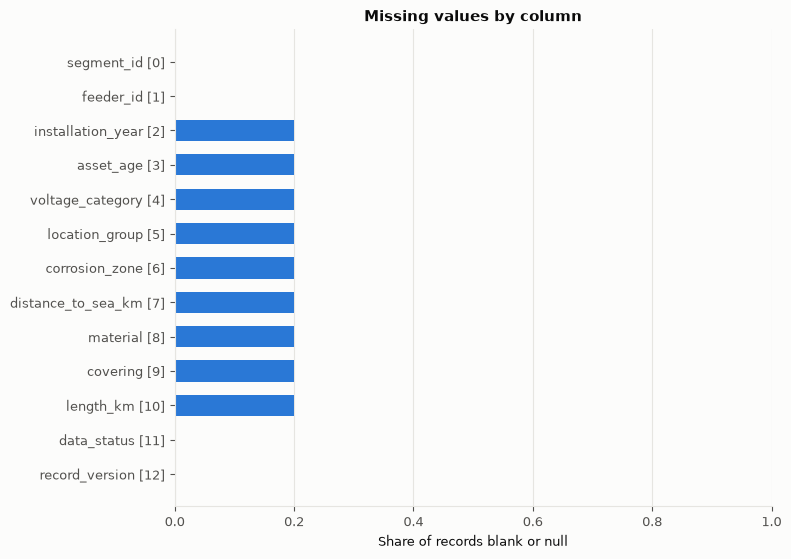

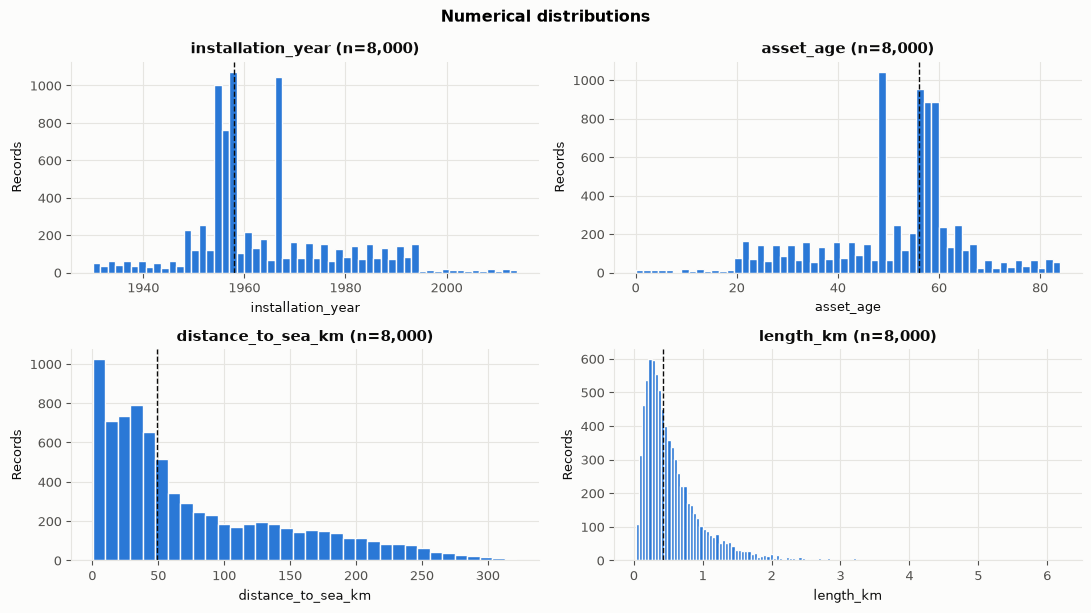

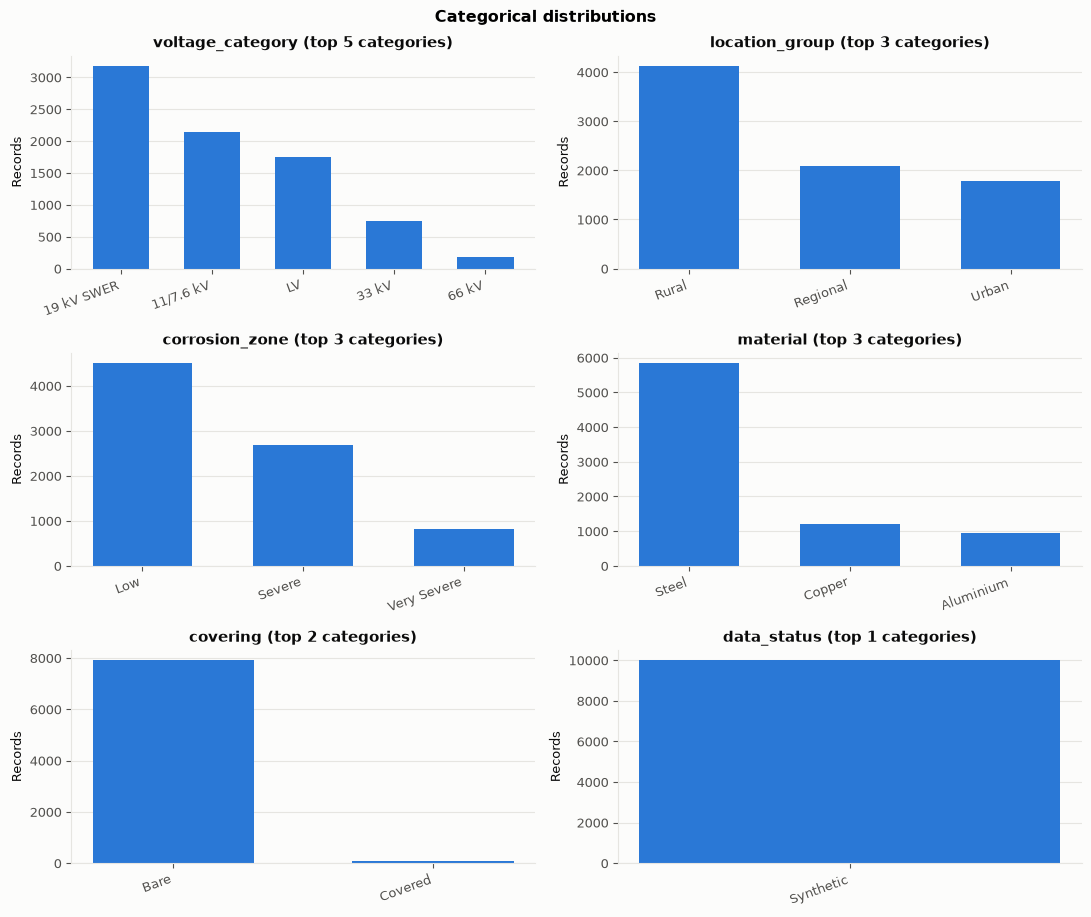

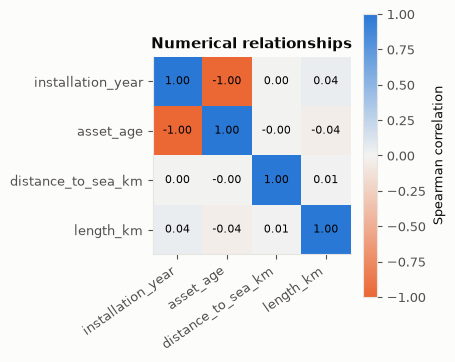

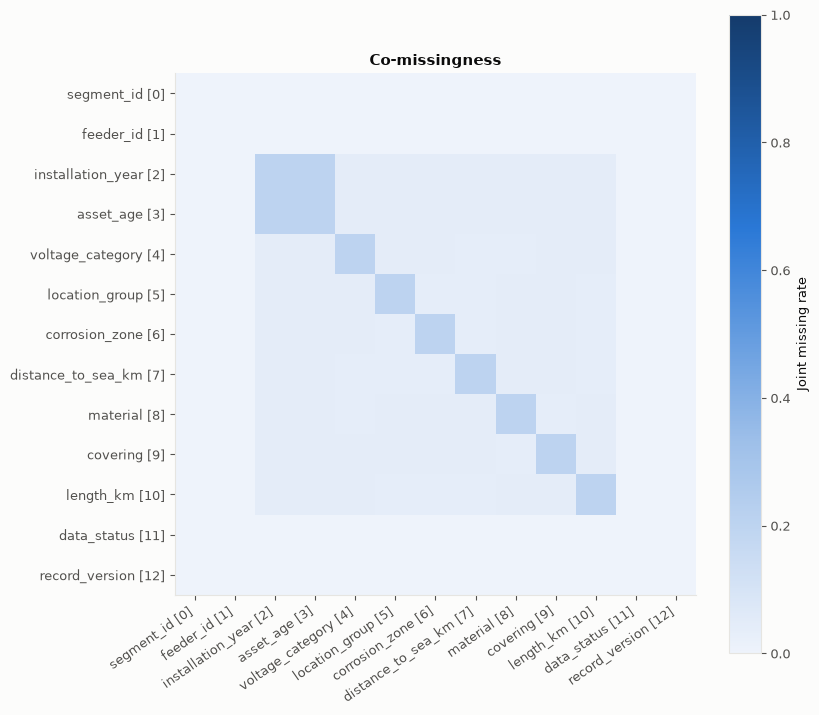

In [ ]:
show_figures(render_discovery_figures(raw_frame, profile))

## 4. Preprocessing and deterministic recovery

Three steps, each audited:

1. **Cleaning** (`cleaning_rules.yaml`): documented corrections with a per-cell log. Rule families are split into *safe* normalisation (whitespace, missing tokens, label case, spelling variants of an allowed label) and *domain decisions* (code mappings such as `AAC -> Aluminium`, sentinel years, out-of-range values, unknown categories). The domain families run only when `approval.<family>.approved` is true and name who approved them; the shipped `code_mappings` are **not approved** (they need a SAPN decision) and are skipped, which the log and the report state.
2. **Schema-aware profiling** of the cleaned, typed records into `profile/`.
3. **Deterministic recovery and leakage control**: `installation_year` is restored from an observed `asset_age` (`snapshot_year - asset_age`, provenance *derived*, range-checked) before any model runs; then the model attributes are selected and the forbidden predictors are refused. `length_km` is not a model attribute and is carried through unchanged; its gaps stay **unresolved** rather than being filled by an unapproved rule.

The dry run first shows what cleaning *would* change; the following cell applies it.

In [ ]:
from src.quality import plan_changes

plan = plan_changes(aligned_frame, schema, rules)
print({k: plan.summary[k] for k in ("rows_in", "rows_out", "cells_changed", "rows_dropped")})
print("Rule families skipped (domain approval pending):", plan.summary["inactive_families"] or "none")
print("Code mappings pending approval (values left as they are):", plan.summary["pending_code_mappings"] or "none")
display(plan.log.groupby(["rule", "column"]).size().reset_index(name="n_cells"))
display(table(plan.log, 15))

{'rows_in': 10000, 'rows_out': 10000, 'cells_changed': 0, 'rows_dropped': 0}
Rule families skipped (domain approval pending): ['code_mappings']
Code mappings pending approval (values left as they are): none


,rule,column,n_cells


,row,record_id,column,old_value,new_value,rule


2026-11-09 17:23:13 WARNING configuration: development run on unapproved configuration (imputation.yaml=changed, pipeline.yaml=changed)
2026-11-09 17:23:13 INFO cleaning: 10000 -> 10000 rows, 0 cells changed, 0 rows dropped (0.1s)
2026-11-09 17:23:13 WARNING configuration: development run on unapproved configuration (imputation.yaml=changed, pipeline.yaml=changed)


Cleaned records: pipeline/outputs/overhead_conductors/run_01/cleaned.csv | log: pipeline/outputs/overhead_conductors/run_01/cleaning_log.csv
{'rows_in': 10000, 'rows_out': 10000, 'cells_changed': 0, 'rows_dropped': 0}


2026-11-09 17:23:15 INFO profiling: 8 tables, 9 figures (1.2s)


,column,role,dtype,n_rows,n_observed,n_missing,missing_rate
0,segment_id,identifier,string,10000,10000,0,0.0
1,feeder_id,group,string,10000,10000,0,0.0
2,installation_year,target,integer,10000,8000,2000,0.2
3,distance_to_sea_km,predictor,float,10000,8000,2000,0.2
4,voltage_category,predictor,category,10000,8000,2000,0.2
5,location_group,predictor,category,10000,8000,2000,0.2
6,corrosion_zone,predictor,category,10000,8000,2000,0.2
7,material,target,category,10000,8000,2000,0.2
8,covering,predictor,category,10000,8000,2000,0.2
9,asset_age,derived,integer,10000,8000,2000,0.2


,pattern,missing_columns,n_missing_columns,n_rows,share
0,0000000,(complete),0,2092,0.2092
1,0000100,corrosion_zone,1,541,0.0541
2,0100000,distance_to_sea_km,1,527,0.0527
3,0000010,material,1,526,0.0526
4,0010000,voltage_category,1,522,0.0522
5,0001000,location_group,1,520,0.0520
6,0000001,covering,1,518,0.0518
7,1000000,installation_year,1,511,0.0511
8,0100010,"distance_to_sea_km, material",2,149,0.0149
9,0011000,"voltage_category, location_group",2,144,0.0144


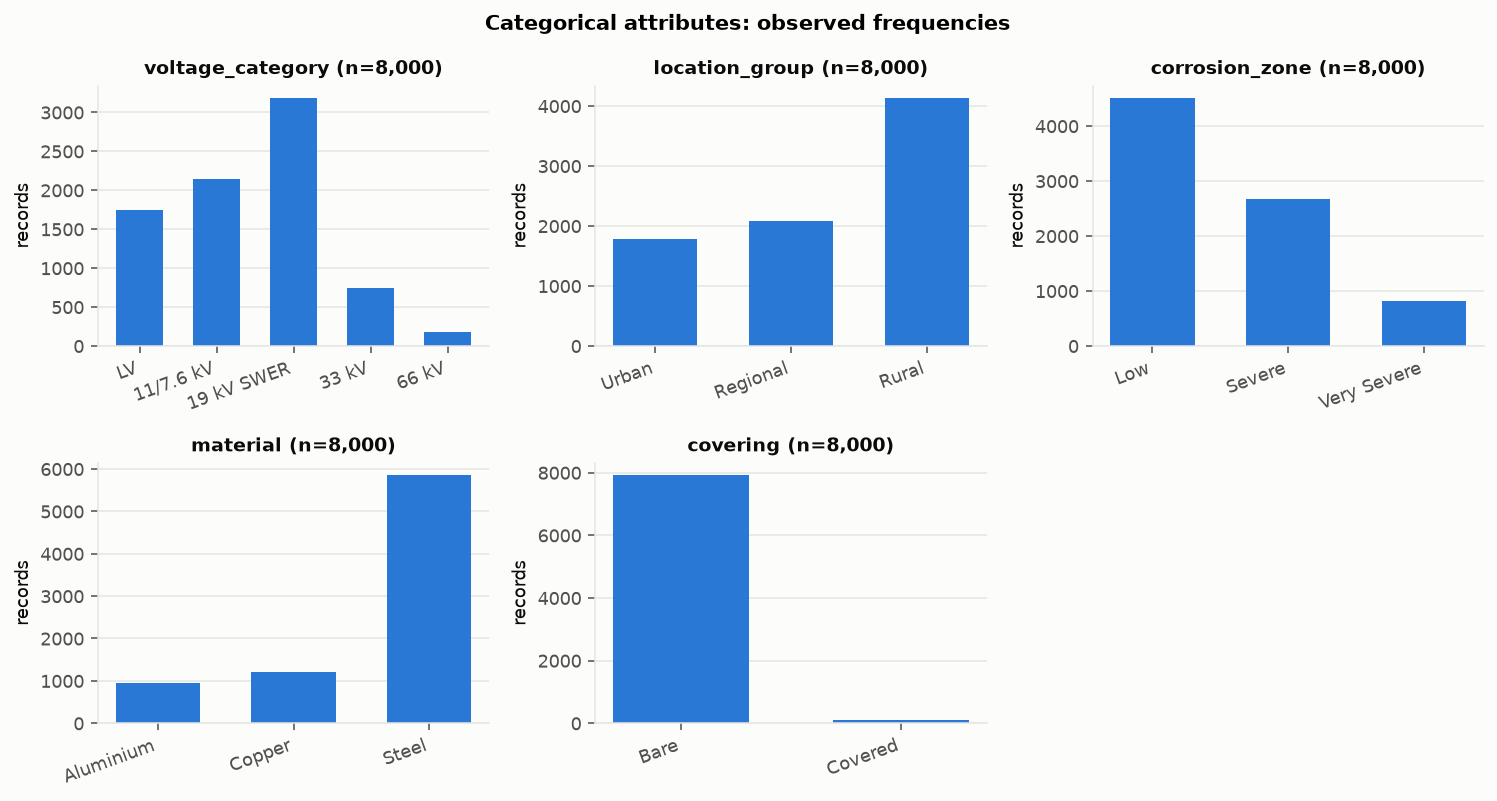

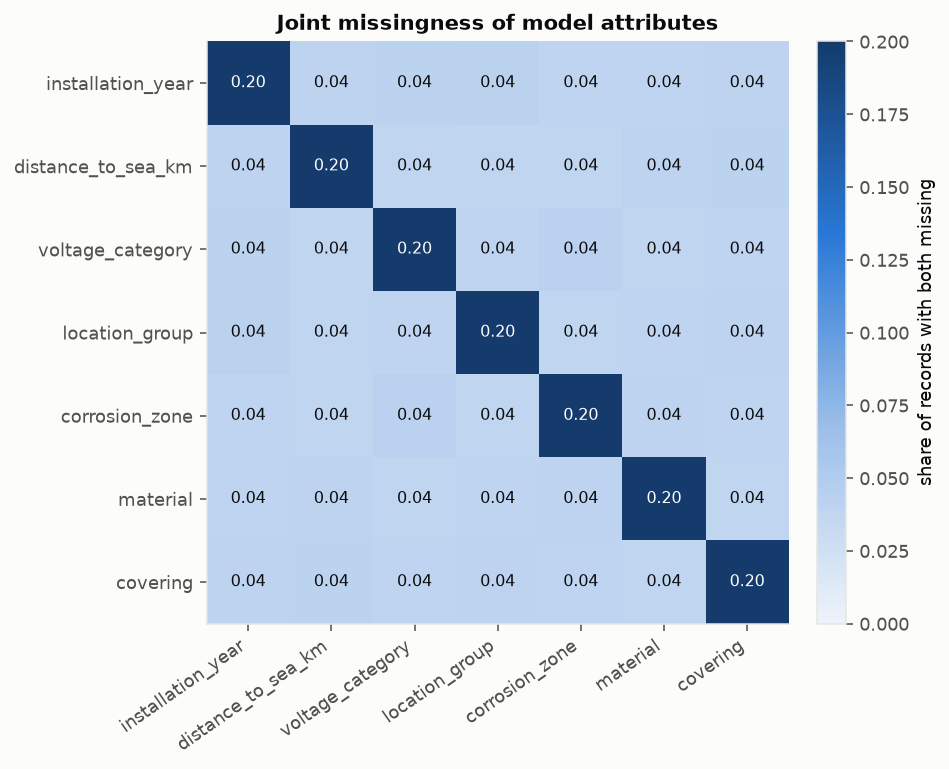

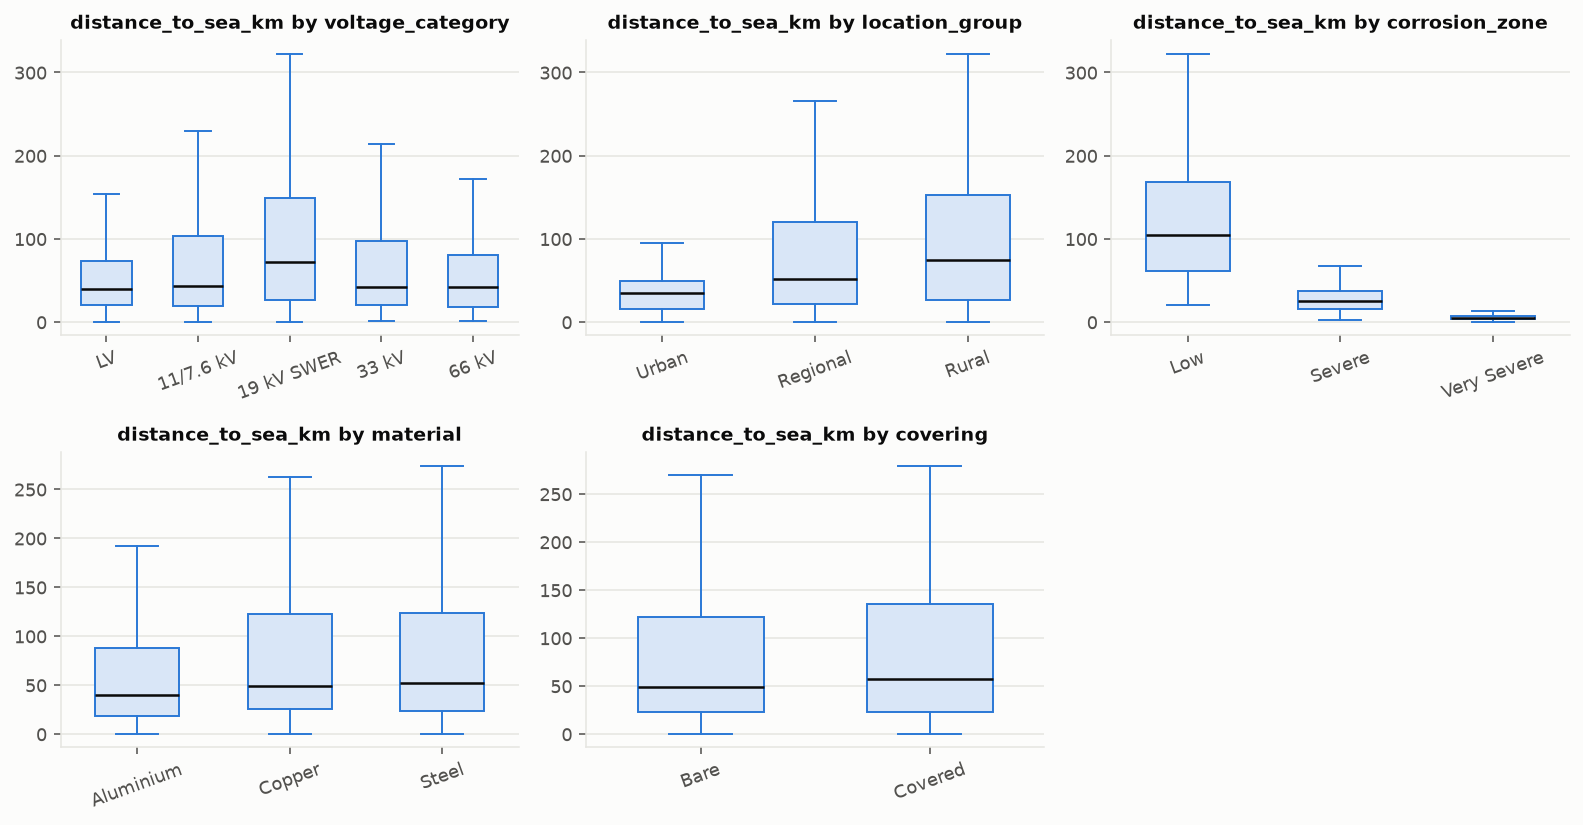

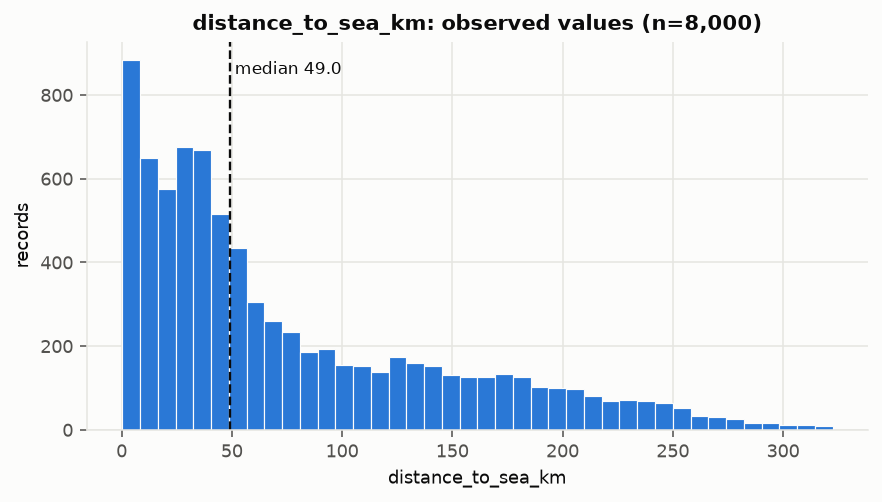

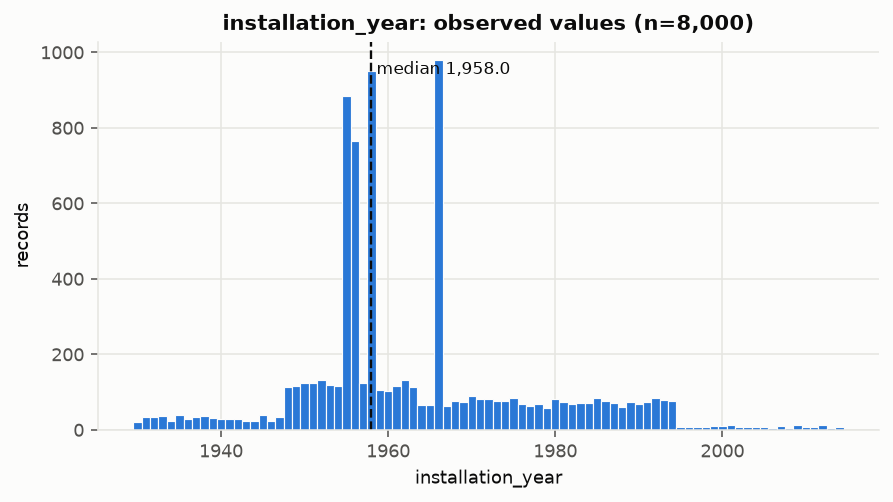

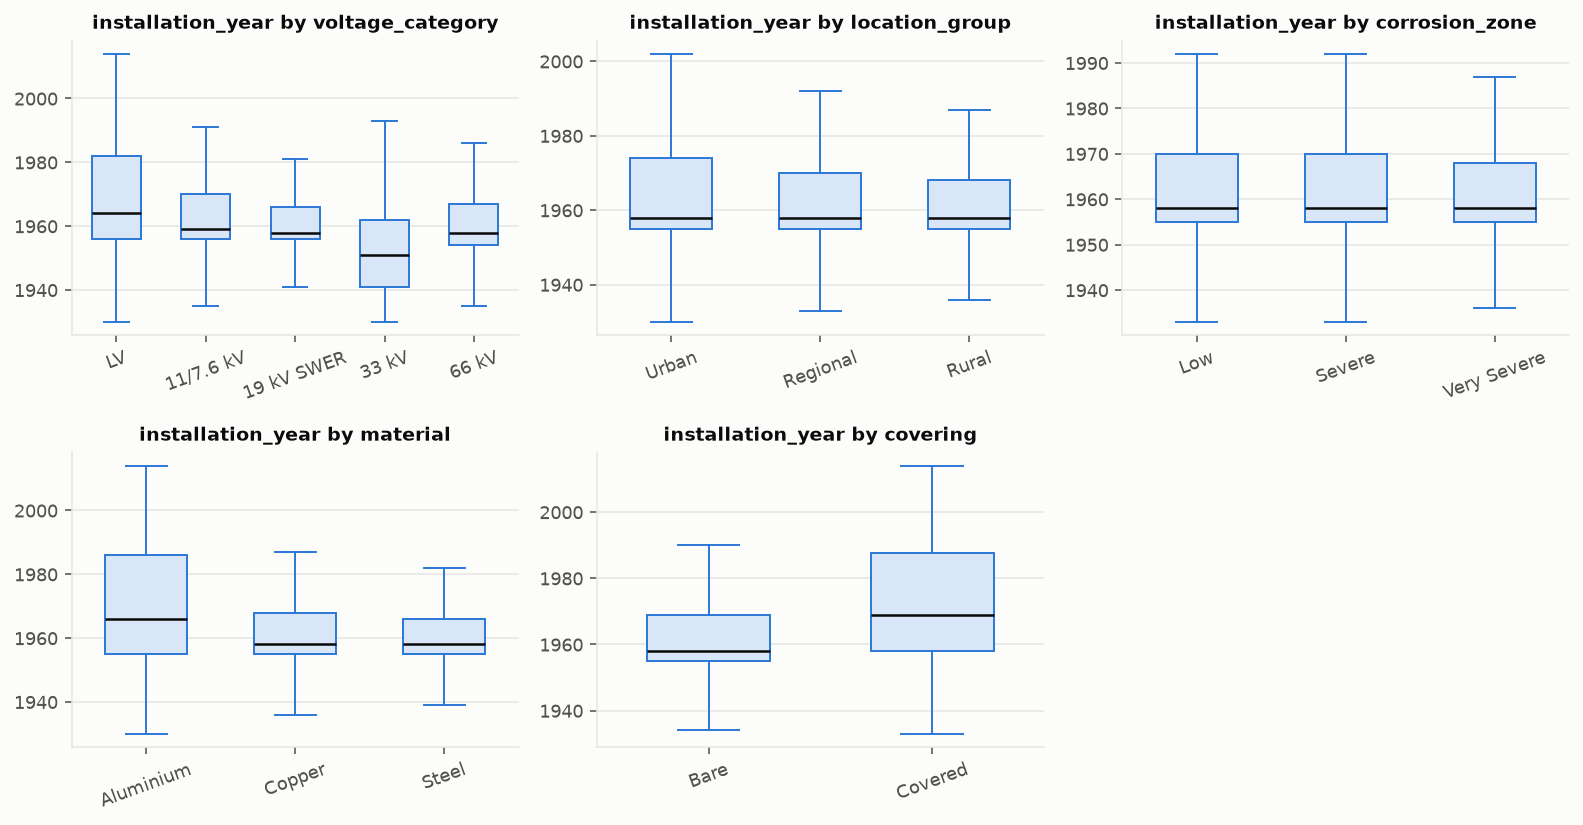

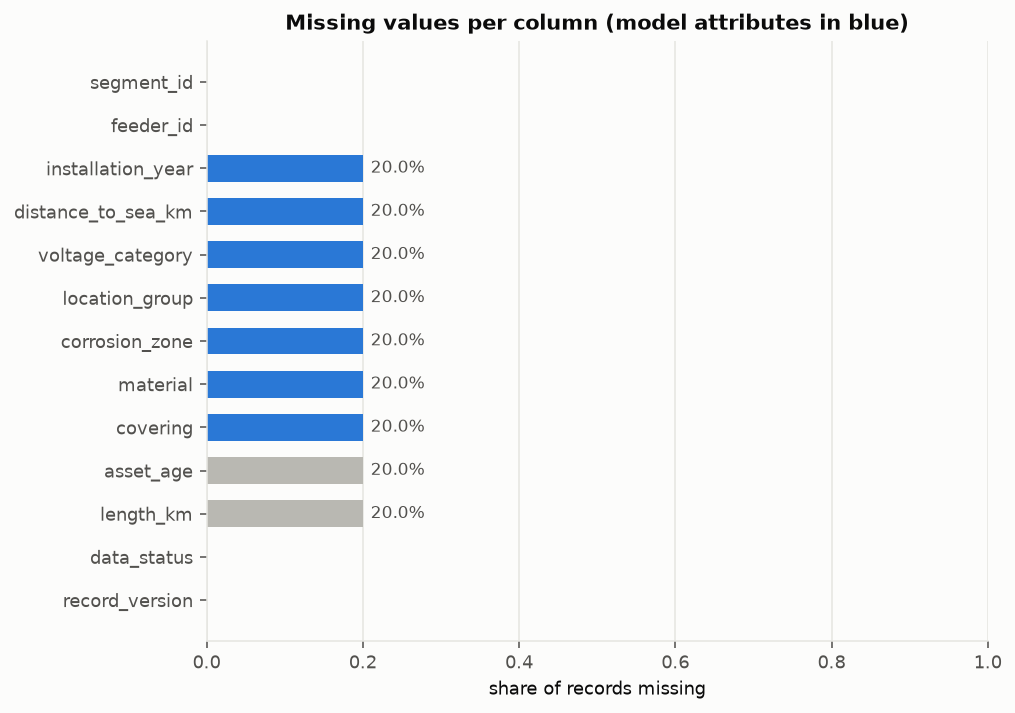

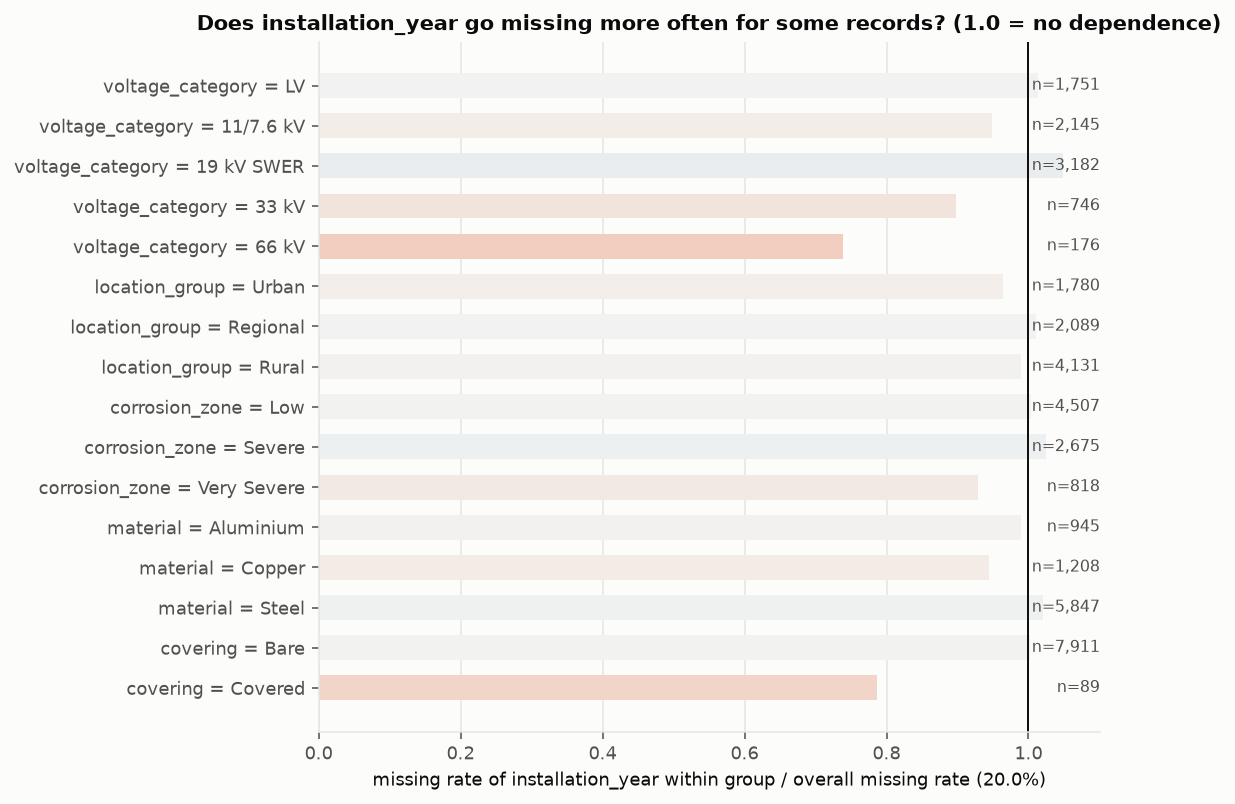

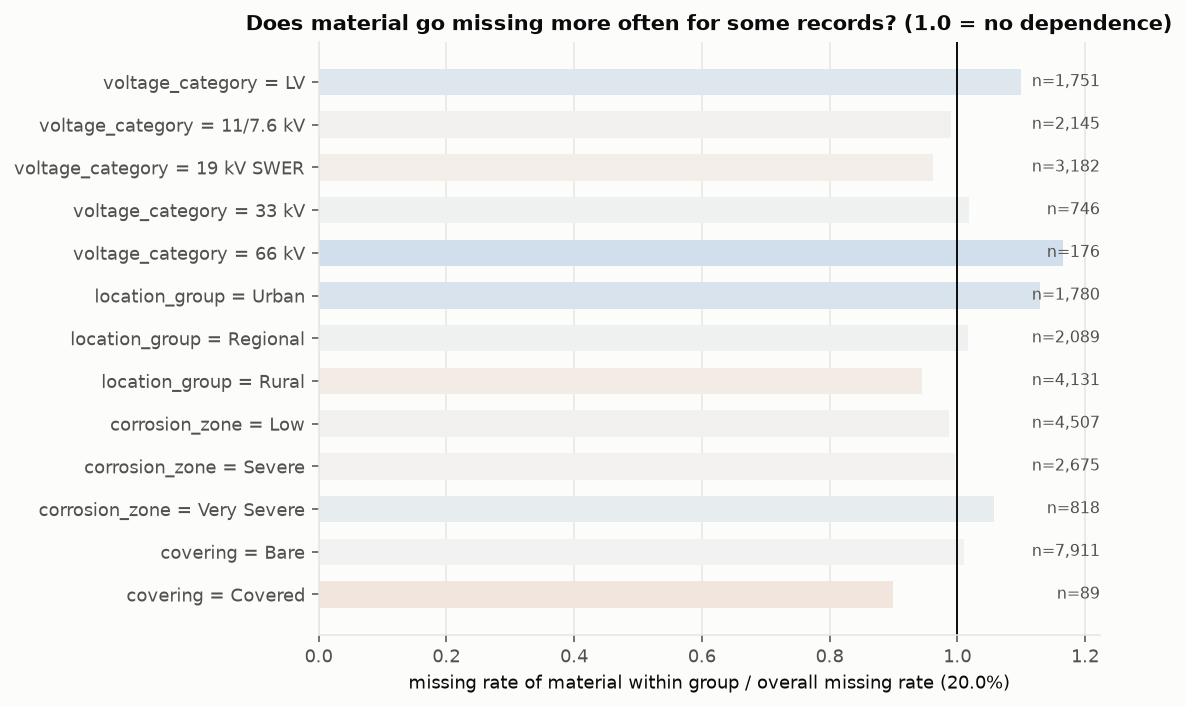

In [ ]:
from src.ingestion import apply_schema_types
from src.pipeline import run_clean, run_profile

cleaned = run_clean(INPUT_CSV, run, settings, frame=aligned_frame)
typed = apply_schema_types(cleaned, schema)
cleaning_meta = read_metadata(run)["cleaning"]
print("Cleaned records:", display_path(run.cleaned, PROJECT_ROOT), "| log:", display_path(run.cleaning_log, PROJECT_ROOT))
print({k: cleaning_meta[k] for k in ("rows_in", "rows_out", "cells_changed", "rows_dropped")})

profile_result = run_profile(run.cleaned, run, settings, frame=typed)
display(profile_result.tables["missingness"])
display(table(profile_result.tables["missing_patterns"], 10))
show_images(sorted(run.profile_dir.glob("*.png")))

In [ ]:
from src.preprocessing import prepare_for_imputation

prepared = prepare_for_imputation(typed, schema, config)   # run_impute repeats this step internally
model_frame = prepared.model_frame
print("Model attributes (fill and predict):", list(model_frame.model_columns))
print("Primary targets:", list(schema.primary_targets))
print("Carried through, never used for prediction:", list(model_frame.passthrough_columns))
print("Forbidden predictors (schema):", list(schema.forbidden_predictors))
display(prepared.recovery.log)
display(missingness_before_after(typed, prepared.frame, model_frame.model_columns))

Model attributes (fill and predict): ['installation_year', 'distance_to_sea_km', 'voltage_category', 'location_group', 'corrosion_zone', 'material', 'covering']
Primary targets: ['installation_year', 'material']
Carried through, never used for prediction: ['feeder_id', 'asset_age', 'length_km', 'data_status', 'record_version']
Forbidden predictors (schema): ['segment_id', 'feeder_id', 'asset_age', 'conductor_type', 'length_km', 'data_status', 'record_version']


,column,from,snapshot_year,n_recovered,n_rejected_out_of_range,n_still_missing,note
0,installation_year,asset_age,2014,0,0,2000,installation_year = 2014 - asset_age where installation_year was missing and asset_age...


,column,missing_before,missing_after,filled
0,installation_year,2000,2000,0
1,distance_to_sea_km,2000,2000,0
2,voltage_category,2000,2000,0
3,location_group,2000,2000,0
4,corrosion_zone,2000,2000,0
5,material,2000,2000,0
6,covering,2000,2000,0


## 5. Choose imputation method

The registry offers interchangeable methods behind one interface (`fit` / `transform` / `fit_transform` returning imputed values, per-cell diagnostics and metadata): `median_mode` (reference), `missforest` (original transductive MissForest) and `predictive_missforest` (fit/transform adaptation with frozen sequential replay). `METHOD` defaults to `imputation.method` in `pipeline.yaml`; hyperparameters come from `imputation.yaml` (`methods.<name>` plus `selected_hyperparameters`, written by the tuning experiment) and are recorded in `run_metadata.json`.

`run_impute` follows `model.mode` in `imputation.yaml`: `train_new` fits a model (optionally tuning first) and can save it to `model.path`; `use_saved` loads that model and calls `transform()` without fitting. `tuning.enabled` controls validation-only tuning, and `tuning.update_selected` optionally commits selected hyperparameters in development mode. Both modes continue through postprocessing (section 6).

In [ ]:
from src.imputation import available_methods, resolve_hyperparameters

METHOD = settings.method            # or any of available_methods()
print("Registered methods:", available_methods())
print("Selected:", METHOD, "| reference:", settings.reference_method)
display(key_values(resolve_hyperparameters(config, METHOD, OVERRIDES or None)))

Registered methods: ('median_mode', 'missforest', 'predictive_missforest')
Selected: predictive_missforest | reference: median_mode


,setting,value
0,n_estimators,100
1,n_passes,5
2,random_state,219
3,n_jobs,1
4,max_features,sqrt
5,max_depth,8
6,min_samples_leaf,10
7,class_weight,None
8,numeric_init,mean
9,unknown_category_policy,ignore


In [ ]:
from src.pipeline import run_impute

output = run_impute(run.cleaned, run, settings, method=METHOD, overrides=OVERRIDES or None, frame=typed)
imputation_meta = read_metadata(run)["imputation"]

print("Cells imputed:", imputation_meta["cells_imputed"], imputation_meta["cells_imputed_by_column"])
print("Model saved:", display_path(imputation_meta["model_path"], PROJECT_ROOT) if imputation_meta["model_path"] else "no (transductive method)")
print("Method metadata:", {k: v for k, v in imputation_meta["method_metadata"].items() if not isinstance(v, (dict, list))})
display(table(output.diagnostics, 10))
if run.convergence.is_file():
    display(pd.read_csv(run.convergence))

2026-11-09 17:23:15 WARNING configuration: development run on unapproved configuration (imputation.yaml=changed, pipeline.yaml=changed)
2026-11-09 17:23:15 INFO imputation: method=predictive_missforest hyperparameters={'n_estimators': 100, 'n_passes': 5, 'random_state': 219, 'n_jobs': 1, 'max_features': 'sqrt', 'max_depth': 8, 'min_samples_leaf': 10, 'class_weight': None, 'numeric_init': 'mean', 'unknown_category_policy': 'ignore', 'min_observed_target': 2} on 10000 rows
2026-11-09 17:23:21 INFO imputation: predictive_missforest filled 14000 cells (6.8s)
2026-11-09 17:23:22 INFO postprocessing: {'observed': 112000, 'derived': 2000, 'imputed': 14000, 'unresolved': 2000}; integrity passed


Cells imputed: 14000 {'corrosion_zone': 2000, 'covering': 2000, 'distance_to_sea_km': 2000, 'installation_year': 2000, 'location_group': 2000, 'material': 2000, 'voltage_category': 2000}
Model saved: pipeline/outputs/models/overhead_conductors/predictive_missforest.joblib
Method metadata: {'method': 'predictive_missforest', 'supports_persistence': True, 'transductive': False, 'runtime_seconds': 0.5523870000033639}


,row,column,kind,imputed,prediction_source,raw_prediction,max_proba,margin,entropy,tree_std,tree_p10,tree_p90,material_probabilities
0,3,installation_year,numeric,1965.0,random_forest,1964.587822,NaN,NaN,NaN,2.569685,1960.164636,1967.477356,NaN
1,9,installation_year,numeric,1964.0,random_forest,1964.434679,NaN,NaN,NaN,3.668544,1961.085740,1968.448282,NaN
2,10,installation_year,numeric,1964.0,random_forest,1964.206581,NaN,NaN,NaN,2.944190,1960.204902,1967.189133,NaN
3,11,installation_year,numeric,1964.0,random_forest,1964.287,NaN,NaN,NaN,3.780077,1961.284162,1966.789530,NaN
4,17,installation_year,numeric,1963.0,random_forest,1963.011057,NaN,NaN,NaN,0.609825,1962.287397,1963.730259,NaN
5,19,installation_year,numeric,1976.0,random_forest,1975.930158,NaN,NaN,NaN,3.158030,1971.866844,1979.898835,NaN
6,23,installation_year,numeric,1967.0,random_forest,1967.314117,NaN,NaN,NaN,2.271635,1964.199482,1970.230614,NaN
7,24,installation_year,numeric,1963.0,random_forest,1963.361711,NaN,NaN,NaN,0.893514,1962.359679,1964.660062,NaN
8,30,installation_year,numeric,1968.0,random_forest,1967.508731,NaN,NaN,NaN,3.048352,1964.134421,1970.622588,NaN
9,32,installation_year,numeric,1970.0,random_forest,1969.745566,NaN,NaN,NaN,4.262063,1965.100957,1976.146429,NaN


,pass,numeric_change,categorical_change,runtime_seconds
0,1,0.000497,0.2129,1.328856
1,2,0.000057,0.0329,1.241934
2,3,0.000002,0.0156,1.213863
3,4,0.000002,0.0115,1.236678
4,5,0.000002,0.0121,1.188502


### Reusing a saved model

A saved `predictive_missforest` model carries a provenance sidecar (fitting rows, identifiers, column roles, constraints, hash). Before `oc-pipeline apply` uses it on new records, `check_compatibility` compares it with the current configuration and input: different model columns are an error; different constraints or unseen category labels are warnings.

In [ ]:
from src.imputation import check_compatibility, load_imputer, read_provenance

saved_path = Path(imputation_meta['model_path']) if imputation_meta.get('model_path') else None
if saved_path and saved_path.is_file():
    saved = load_imputer(saved_path)
    provenance = read_provenance(saved_path)
    compatibility = check_compatibility(
        saved_path, saved,
        numeric_columns=model_frame.numeric_columns, categorical_columns=model_frame.categorical_columns,
        constraints=config.constraints, frame=prepared.frame,
    )
    print("Fitted on", provenance.get("n_fitting_rows"), "rows at", provenance.get("created_utc"))
    print("Compatibility errors:", compatibility["errors"] or "none")
    print("Compatibility warnings:", compatibility["warnings"] or "none")
else:
    print("No persisted model for this method (transductive); use `impute` on each new table.")

Fitted on 10000 rows at 2026-11-09T06:53:22+00:00
Compatibility errors: none
Compatibility warnings: none


## 6. Postprocessing and cell provenance

After imputation the derived column is filled or recomputed from its (possibly imputed) source, integer columns are exported as integers, and every cell of `final_imputed.csv` is classified: **observed** (left exactly as cleaned), **derived** (deterministic rule), **imputed** (the method) or **unresolved** (still missing). The integrity checks confirm that no observed value changed and that constraints hold; a failure raises before any file is reported as final.

In [ ]:
from src.ingestion import load_records

final = apply_schema_types(load_records(run.imputed, schema).frame, schema)
provenance_summary = pd.read_csv(run.provenance_summary)
cells = pd.read_csv(run.cell_provenance)

print("Provenance totals:", imputation_meta["provenance"]["totals"])
print("Unresolved columns:", imputation_meta["provenance"]["unresolved_columns"] or "none")
print("Integrity checks passed:", imputation_meta["integrity_passed"])
display(provenance_summary)
display(missingness_before_after(typed, final, final.columns))

Provenance totals: {'observed': 112000, 'derived': 2000, 'imputed': 14000, 'unresolved': 2000, 'n_cells': 130000}
Unresolved columns: {'length_km': {'n_cells': 2000, 'reason': 'not a model attribute'}}
Integrity checks passed: True


,column,observed,derived,imputed,unresolved,n_cells
0,segment_id,10000,0,0,0,10000
1,feeder_id,10000,0,0,0,10000
2,installation_year,8000,0,2000,0,10000
3,distance_to_sea_km,8000,0,2000,0,10000
4,voltage_category,8000,0,2000,0,10000
5,location_group,8000,0,2000,0,10000
6,corrosion_zone,8000,0,2000,0,10000
7,material,8000,0,2000,0,10000
8,covering,8000,0,2000,0,10000
9,asset_age,8000,2000,0,0,10000


,column,missing_before,missing_after,filled
0,segment_id,0,0,0
1,feeder_id,0,0,0
2,installation_year,2000,0,2000
3,distance_to_sea_km,2000,0,2000
4,voltage_category,2000,0,2000
5,location_group,2000,0,2000
6,corrosion_zone,2000,0,2000
7,material,2000,0,2000
8,covering,2000,0,2000
9,asset_age,2000,0,2000


In [ ]:
display(table(cells[cells["status"] == "imputed"], 10))
display(table(cells[cells["status"] == "derived"], 10))
display(pd.read_csv(run.derived_log))
display(final.head(10))

,record_id,column,status,method,value,detail
0,SEG_000004,installation_year,imputed,predictive_missforest,1965,prediction_source=random_forest; tree_std=2.570
1,SEG_000010,installation_year,imputed,predictive_missforest,1964,prediction_source=random_forest; tree_std=3.669
2,SEG_000011,installation_year,imputed,predictive_missforest,1964,prediction_source=random_forest; tree_std=2.944
3,SEG_000012,installation_year,imputed,predictive_missforest,1964,prediction_source=random_forest; tree_std=3.780
4,SEG_000018,installation_year,imputed,predictive_missforest,1963,prediction_source=random_forest; tree_std=0.610
5,SEG_000020,installation_year,imputed,predictive_missforest,1976,prediction_source=random_forest; tree_std=3.158
6,SEG_000024,installation_year,imputed,predictive_missforest,1967,prediction_source=random_forest; tree_std=2.272
7,SEG_000025,installation_year,imputed,predictive_missforest,1963,prediction_source=random_forest; tree_std=0.894
8,SEG_000031,installation_year,imputed,predictive_missforest,1968,prediction_source=random_forest; tree_std=3.048
9,SEG_000033,installation_year,imputed,predictive_missforest,1970,prediction_source=random_forest; tree_std=4.262


,record_id,column,status,method,value,detail
14000,SEG_000004,asset_age,derived,snapshot_year_minus,49,asset_age = 2014 - installation_year
14001,SEG_000010,asset_age,derived,snapshot_year_minus,50,asset_age = 2014 - installation_year
14002,SEG_000011,asset_age,derived,snapshot_year_minus,50,asset_age = 2014 - installation_year
14003,SEG_000012,asset_age,derived,snapshot_year_minus,50,asset_age = 2014 - installation_year
14004,SEG_000018,asset_age,derived,snapshot_year_minus,51,asset_age = 2014 - installation_year
14005,SEG_000020,asset_age,derived,snapshot_year_minus,38,asset_age = 2014 - installation_year
14006,SEG_000024,asset_age,derived,snapshot_year_minus,47,asset_age = 2014 - installation_year
14007,SEG_000025,asset_age,derived,snapshot_year_minus,51,asset_age = 2014 - installation_year
14008,SEG_000031,asset_age,derived,snapshot_year_minus,46,asset_age = 2014 - installation_year
14009,SEG_000033,asset_age,derived,snapshot_year_minus,44,asset_age = 2014 - installation_year


,column,source,method,snapshot_year,n_filled,n_recomputed_after_source_imputed,n_inconsistent_existing,n_still_missing,note
0,asset_age,installation_year,snapshot_year_minus,2014,2000,0,0,0,existing values kept unless their source was imputed


,segment_id,feeder_id,installation_year,distance_to_sea_km,voltage_category,location_group,corrosion_zone,material,covering,asset_age,length_km,data_status,record_version
0,SEG_000001,G_FDR_021,1973.0,9.40,LV,Regional,Severe,Steel,Bare,41.0,1.5906,Synthetic,Complete reference
1,SEG_000002,R_FDR_034,1955.0,233.85,33 kV,Rural,Low,Steel,Bare,59.0,1.0080,Synthetic,Complete reference
2,SEG_000003,U_FDR_020,1962.0,10.62,LV,Urban,Severe,Steel,Bare,52.0,0.1153,Synthetic,Complete reference
3,SEG_000004,U_FDR_005,1965.0,25.49,LV,Urban,Severe,Steel,Bare,49.0,0.2395,Synthetic,Complete reference
4,SEG_000005,R_FDR_022,1983.0,142.88,19 kV SWER,Rural,Low,Steel,Bare,31.0,0.6563,Synthetic,Complete reference
5,SEG_000006,U_FDR_013,1960.0,3.24,33 kV,Urban,Very Severe,Steel,Bare,54.0,0.0828,Synthetic,Complete reference
6,SEG_000007,G_FDR_023,1958.0,208.97,LV,Regional,Low,Steel,Bare,56.0,0.7184,Synthetic,Complete reference
7,SEG_000008,R_FDR_013,1966.0,32.86,11/7.6 kV,Rural,Severe,Steel,Bare,48.0,0.7763,Synthetic,Complete reference
8,SEG_000009,G_FDR_010,1966.0,31.24,11/7.6 kV,Regional,Severe,Steel,Bare,48.0,NaN,Synthetic,Complete reference
9,SEG_000010,R_FDR_043,1964.0,4.55,LV,Rural,Very Severe,Steel,Bare,50.0,1.4330,Synthetic,Complete reference


## 7. Evaluation and diagnostics

Two different questions, kept apart:

**Operational checks** (`run_validate`) need no ground truth: integrity, distribution shift between observed and imputed values, low-confidence cells, and the *same-table reconstruction check* (hide 10 % of currently observed cells, refit on the masked table, score the hidden cells). The reconstruction check tells how well *known* values are reconstructed on this table; it says nothing about the originally missing cells, which have no truth.

**Evaluation mode** (`run_evaluate`) needs a complete reference. Records are divided into fit / validation / test with the asset's configured partition policy, the measured file's originally missing cells are scored where the truth is known, and only the **test** partition is scored. `unseen_records` fits on the fit partition and transforms the test partition (the operational situation for a persistable method); `transductive` runs `fit_transform` on fit + test together. The validation partition is reserved for tuning and is never scored here. On synthetic data these figures describe the generator, not SAPN's population.

2026-11-09 17:23:23 WARNING configuration: development run on unapproved configuration (imputation.yaml=changed, pipeline.yaml=changed)
2026-11-09 17:23:23 INFO validation: integrity passed (0 failed checks)
2026-11-09 17:23:30 INFO validation: reconstruction repeat 0 method predictive_missforest (6.2s)
2026-11-09 17:23:30 INFO validation: reconstruction repeat 0 method median_mode (0.1s)


Integrity passed: True | failed checks: 0


,check,column,status,count,detail
0,row_count_unchanged,NaN,pass,0,"10000 in, 10000 out"
1,columns_unchanged,NaN,pass,0,NaN
2,identifier_order_unchanged,segment_id,pass,0,NaN
3,no_missing_after_imputation,installation_year,pass,0,NaN
4,no_missing_after_imputation,distance_to_sea_km,pass,0,NaN
5,no_missing_after_imputation,voltage_category,pass,0,NaN
6,no_missing_after_imputation,location_group,pass,0,NaN
7,no_missing_after_imputation,corrosion_zone,pass,0,NaN
8,no_missing_after_imputation,material,pass,0,NaN
9,no_missing_after_imputation,covering,pass,0,NaN


,variable,variable_type,n_observed,n_imputed,observed_mean,imputed_mean,observed_std,imputed_std,std_ratio,wasserstein_1,ks_statistic,ks_pvalue,total_variation,majority_share_observed,majority_share_imputed,completed_vs_observed_w1,completed_vs_observed_tv
0,installation_year,numeric,8000,2000,1963.42825,1963.660500,14.346274,4.227786,0.294696,8.667250,0.468125,7.145474e-319,NaN,NaN,NaN,1.733450,NaN
1,distance_to_sea_km,numeric,8000,2000,76.84954,84.339145,71.083880,53.040438,0.746167,29.319247,0.254000,3.142704e-91,NaN,NaN,NaN,5.863849,NaN
2,voltage_category,categorical,8000,2000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.213750,0.397750,0.6115,NaN,0.042750
3,location_group,categorical,8000,2000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.164125,0.516375,0.6805,NaN,0.032825
4,corrosion_zone,categorical,8000,2000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.069125,0.563375,0.6325,NaN,0.013825
5,material,categorical,8000,2000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.238625,0.730875,0.9695,NaN,0.047725
6,covering,categorical,8000,2000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.011125,0.988875,1.0000,NaN,0.002225


,method,variable,variable_type,n_masked,mae,rmse,median_absolute_error,nrmse,signed_bias,accuracy,balanced_accuracy,macro_f1,mae_std,macro_f1_std,n_repeats
0,predictive_missforest,installation_year,numeric,800,10.938750,14.101906,8.00000,0.977403,0.236250,NaN,NaN,NaN,NaN,NaN,1
1,predictive_missforest,distance_to_sea_km,numeric,800,43.207436,60.096595,25.81464,0.874058,14.931709,NaN,NaN,NaN,NaN,NaN,1
2,predictive_missforest,voltage_category,categorical,800,NaN,NaN,NaN,NaN,NaN,0.518750,0.339175,0.336598,NaN,NaN,1
3,predictive_missforest,location_group,categorical,800,NaN,NaN,NaN,NaN,NaN,0.593750,0.510094,0.516176,NaN,NaN,1
4,predictive_missforest,corrosion_zone,categorical,801,NaN,NaN,NaN,NaN,NaN,0.754057,0.621507,0.654343,NaN,NaN,1
5,predictive_missforest,material,categorical,800,NaN,NaN,NaN,NaN,NaN,0.720000,0.346665,0.318912,NaN,NaN,1
6,predictive_missforest,covering,categorical,800,NaN,NaN,NaN,NaN,NaN,0.988750,0.500000,0.497172,NaN,NaN,1
7,median_mode,installation_year,numeric,800,10.587500,15.424737,8.00000,1.069088,-5.455000,NaN,NaN,NaN,NaN,NaN,1
8,median_mode,distance_to_sea_km,numeric,800,53.051725,74.595420,36.34000,1.084932,-28.932925,NaN,NaN,NaN,NaN,NaN,1
9,median_mode,voltage_category,categorical,800,NaN,NaN,NaN,NaN,NaN,0.397500,0.200000,0.113775,NaN,NaN,1


Low-confidence cells listed: {'n_cells': 14000, 'n_scored': 14000, 'n_listed': 1400, 'fraction': 0.1, 'listed_by_column': {'corrosion_zone': 200, 'covering': 200, 'distance_to_sea_km': 200, 'installation_year': 200, 'location_group': 200, 'material': 200, 'voltage_category': 200}, 'fallback_cells': 0}


,row,segment_id,column,kind,imputed,prediction_source,raw_prediction,max_proba,margin,entropy,tree_std,tree_p10,tree_p90,material_probabilities,confidence_signal,confidence_rank
0,1490,SEG_001491,corrosion_zone,categorical,Severe,random_forest,Severe,0.359877,0.000776,1.092273,NaN,NaN,NaN,NaN,0.000776,0.0005
1,6457,SEG_006458,corrosion_zone,categorical,Severe,random_forest,Severe,0.421539,0.002649,1.021494,NaN,NaN,NaN,NaN,0.002649,0.0010
2,7675,SEG_007676,corrosion_zone,categorical,Low,random_forest,Low,0.469134,0.004461,0.890932,NaN,NaN,NaN,NaN,0.004461,0.0015
3,976,SEG_000977,corrosion_zone,categorical,Very Severe,random_forest,Very Severe,0.422779,0.004995,1.021353,NaN,NaN,NaN,NaN,0.004995,0.0020
4,2618,SEG_002619,corrosion_zone,categorical,Severe,random_forest,Severe,0.421635,0.005177,1.023723,NaN,NaN,NaN,NaN,0.005177,0.0025
5,7212,SEG_007213,corrosion_zone,categorical,Severe,random_forest,Severe,0.459829,0.006872,0.928713,NaN,NaN,NaN,NaN,0.006872,0.0030
6,9639,SEG_009640,corrosion_zone,categorical,Severe,random_forest,Severe,0.422822,0.007550,1.023705,NaN,NaN,NaN,NaN,0.007550,0.0035
7,4929,SEG_004930,corrosion_zone,categorical,Very Severe,random_forest,Very Severe,0.424837,0.010800,1.022925,NaN,NaN,NaN,NaN,0.010800,0.0040
8,8099,SEG_008100,corrosion_zone,categorical,Very Severe,random_forest,Very Severe,0.445573,0.011099,0.976762,NaN,NaN,NaN,NaN,0.011099,0.0045
9,7924,SEG_007925,corrosion_zone,categorical,Severe,random_forest,Severe,0.437235,0.011706,0.997857,NaN,NaN,NaN,NaN,0.011706,0.0050


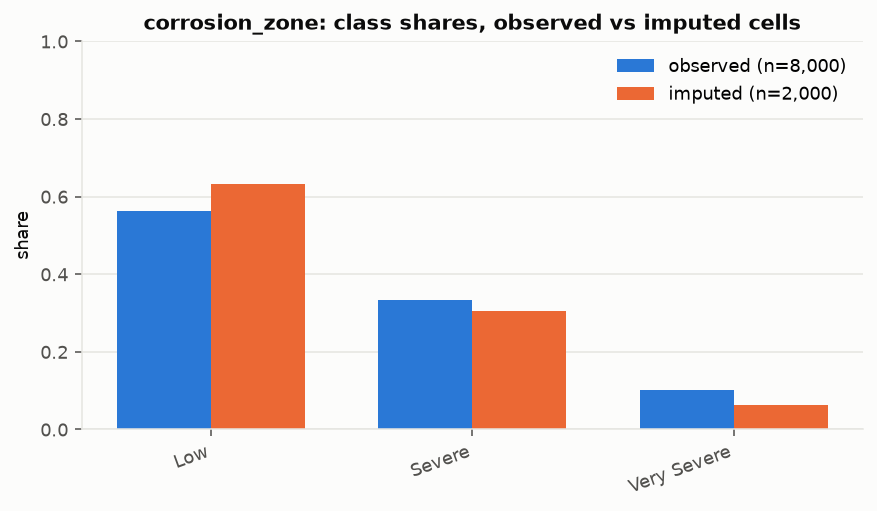

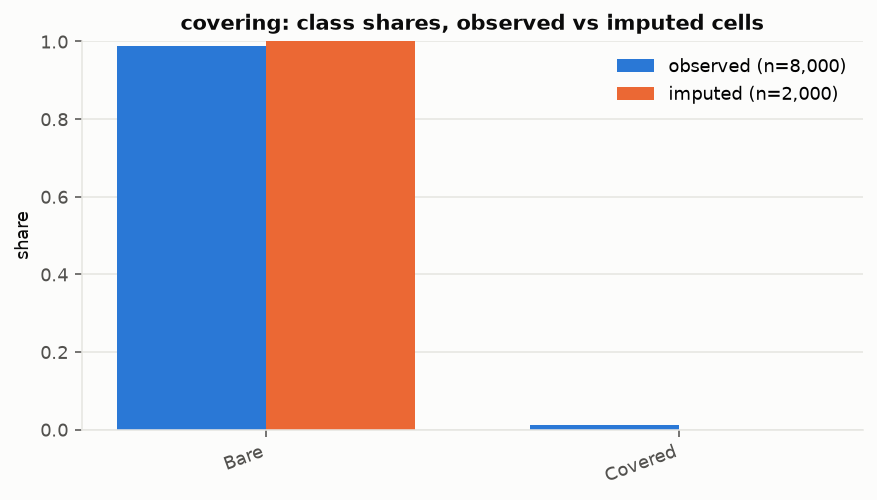

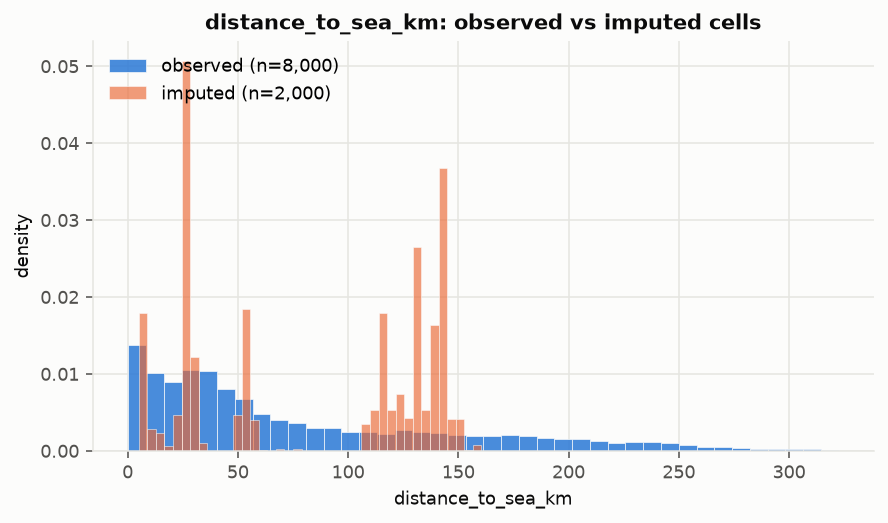

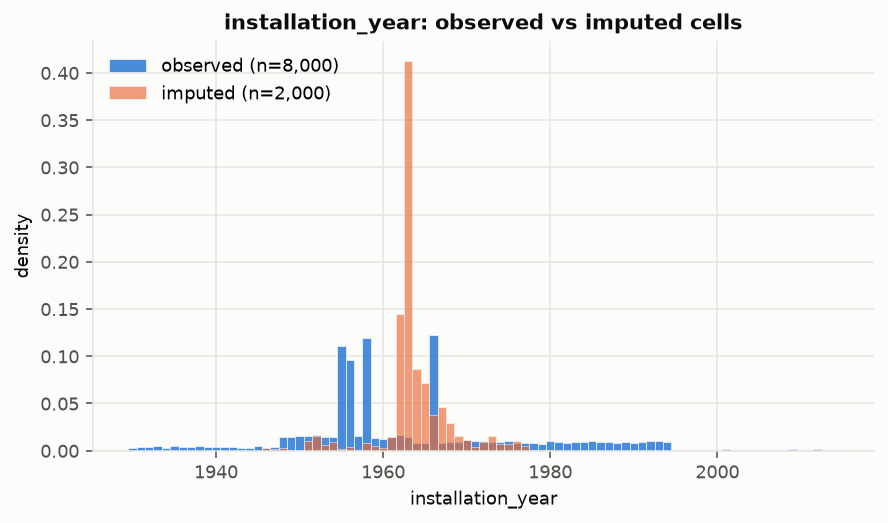

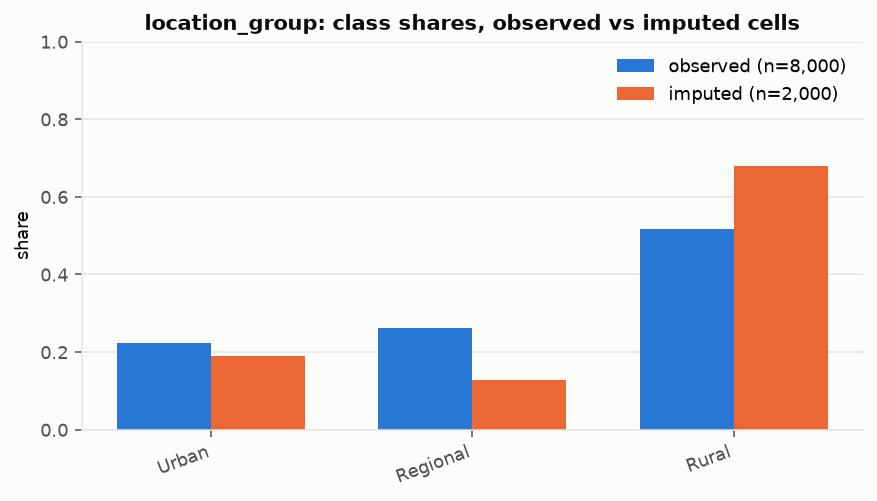

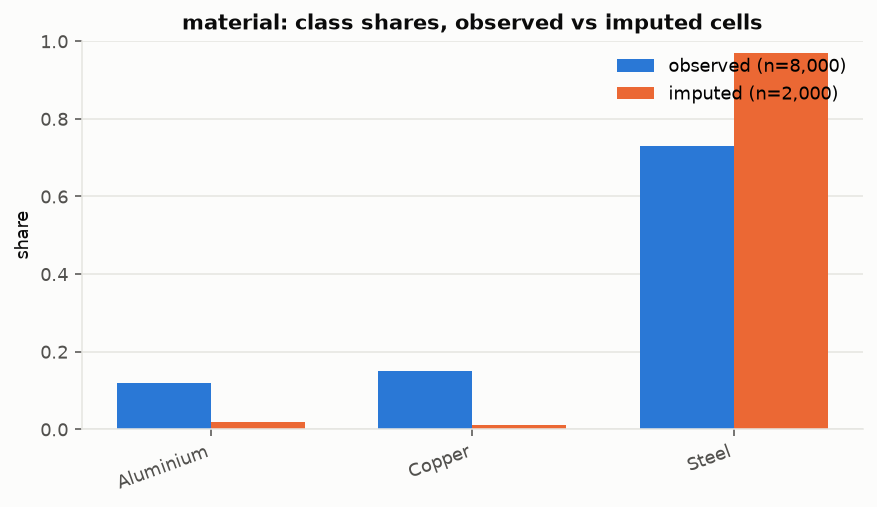

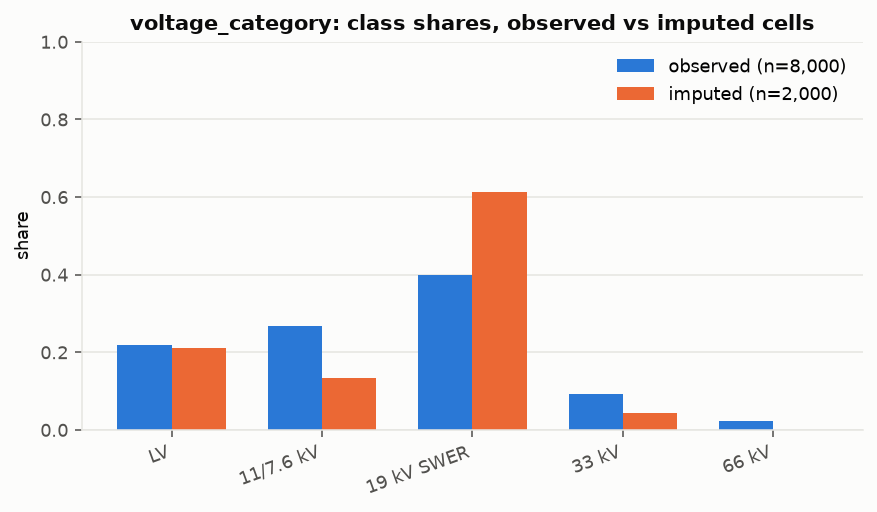

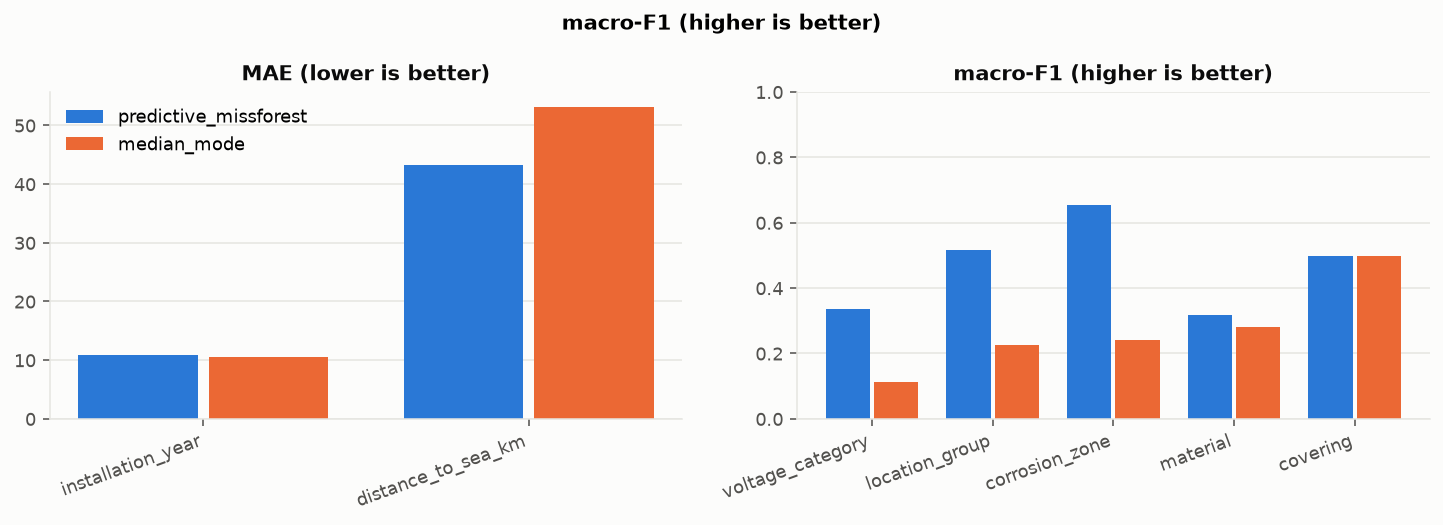

In [ ]:
from src.pipeline import run_validate

validation = run_validate(run, settings)
vdir = run.validation_dir
print("Integrity passed:", validation["integrity_passed"], "| failed checks:", validation["integrity_failed_checks"])
display(pd.read_csv(vdir / "integrity_checks.csv"))
display(pd.read_csv(vdir / "distribution_checks.csv"))
if (vdir / "reconstruction_summary.csv").is_file():
    display(pd.read_csv(vdir / "reconstruction_summary.csv"))
if (vdir / "low_confidence_cells.csv").is_file():
    print("Low-confidence cells listed:", validation["confidence"])
    display(table(pd.read_csv(vdir / "low_confidence_cells.csv"), 10))
show_images(sorted((vdir / "figures").glob("*.png")))

2026-11-09 17:23:30 WARNING configuration: development run on unapproved configuration (imputation.yaml=changed, pipeline.yaml=changed)


2026-11-09 17:23:30 INFO evaluation: mask source masked_input; partitions {'validation': 1450, 'test': 2538, 'fit': 6012}; methods ['predictive_missforest', 'median_mode']
2026-11-09 17:23:35 INFO evaluation: unseen_records predictive_missforest repeat 0 (4.5s)
2026-11-09 17:23:35 INFO evaluation: unseen_records median_mode repeat 0 (0.0s)
2026-11-09 17:23:40 INFO evaluation: transductive predictive_missforest repeat 0 (5.8s)
2026-11-09 17:23:40 INFO evaluation: transductive median_mode repeat 0 (0.0s)
2026-11-09 17:23:41 INFO evaluation complete (10.7s): /Users/zisanaalam/Desktop/GitHub/team19-asset-data/pipeline/outputs/overhead_conductors/run_01/evaluation


Truth: pipeline/data/overhead_conductors/conductors_synthetic_complete.csv | measured input (cleaned): pipeline/outputs/overhead_conductors/run_01/cleaned.csv
Evaluation: masked_input | partitions: {'validation': 1450, 'test': 2538, 'fit': 6012}
Methods and hyperparameters: {'predictive_missforest': {'n_estimators': 100, 'n_passes': 5, 'random_state': 219, 'n_jobs': 1, 'max_features': 'sqrt', 'max_depth': 8, 'min_samples_leaf': 10, 'class_weight': None, 'numeric_init': 'mean', 'unknown_category_policy': 'ignore', 'min_observed_target': 2}, 'median_mode': {'numeric_strategy': 'median', 'categorical_strategy': 'mode'}}


,protocol,method,variable,variable_type,n_masked,mae,rmse,median_absolute_error,nrmse,signed_bias,accuracy,balanced_accuracy,macro_f1,fit_seconds,mae_std,macro_f1_std,n_repeats,within_5_years
0,unseen_records,predictive_missforest,installation_year,numeric,522,10.932950,13.838353,9.0,0.965591,0.473180,NaN,NaN,NaN,4.462843,NaN,NaN,1,0.279693
5,unseen_records,predictive_missforest,material,categorical,516,NaN,NaN,NaN,NaN,NaN,0.724806,0.335969,0.292250,4.462843,NaN,NaN,1,NaN
7,unseen_records,median_mode,installation_year,numeric,522,10.731801,15.358176,8.0,1.071639,-5.521073,NaN,NaN,NaN,0.014976,NaN,NaN,1,0.434866
12,unseen_records,median_mode,material,categorical,516,NaN,NaN,NaN,NaN,NaN,0.730620,0.333333,0.281448,0.014976,NaN,NaN,1,NaN
14,transductive,predictive_missforest,installation_year,numeric,522,10.785441,13.758035,8.0,0.959987,0.268199,NaN,NaN,NaN,5.817936,NaN,NaN,1,0.291188
19,transductive,predictive_missforest,material,categorical,516,NaN,NaN,NaN,NaN,NaN,0.726744,0.340677,0.302282,5.817936,NaN,NaN,1,NaN
21,transductive,median_mode,installation_year,numeric,522,10.731801,15.358176,8.0,1.071639,-5.521073,NaN,NaN,NaN,0.029820,NaN,NaN,1,0.434866
26,transductive,median_mode,material,categorical,516,NaN,NaN,NaN,NaN,NaN,0.730620,0.333333,0.281448,0.029820,NaN,NaN,1,NaN


,protocol,method,variable,variable_type,n_masked,mae,rmse,median_absolute_error,nrmse,signed_bias,accuracy,balanced_accuracy,macro_f1,fit_seconds,mae_std,macro_f1_std,n_repeats,within_5_years
0,unseen_records,predictive_missforest,installation_year,numeric,522,10.932950,13.838353,9.000000,0.965591,0.473180,NaN,NaN,NaN,4.462843,NaN,NaN,1,0.279693
1,unseen_records,predictive_missforest,distance_to_sea_km,numeric,492,35.657245,51.669968,20.653359,0.750566,6.662459,NaN,NaN,NaN,4.462843,NaN,NaN,1,NaN
2,unseen_records,predictive_missforest,voltage_category,categorical,530,NaN,NaN,NaN,NaN,NaN,0.554717,0.368184,0.344270,4.462843,NaN,NaN,1,NaN
3,unseen_records,predictive_missforest,location_group,categorical,504,NaN,NaN,NaN,NaN,NaN,0.640873,0.536221,0.530553,4.462843,NaN,NaN,1,NaN
4,unseen_records,predictive_missforest,corrosion_zone,categorical,535,NaN,NaN,NaN,NaN,NaN,0.736449,0.683365,0.699585,4.462843,NaN,NaN,1,NaN
5,unseen_records,predictive_missforest,material,categorical,516,NaN,NaN,NaN,NaN,NaN,0.724806,0.335969,0.292250,4.462843,NaN,NaN,1,NaN
6,unseen_records,predictive_missforest,covering,categorical,486,NaN,NaN,NaN,NaN,NaN,0.991770,0.500000,0.497934,4.462843,NaN,NaN,1,NaN
7,unseen_records,median_mode,installation_year,numeric,522,10.731801,15.358176,8.000000,1.071639,-5.521073,NaN,NaN,NaN,0.014976,NaN,NaN,1,0.434866
8,unseen_records,median_mode,distance_to_sea_km,numeric,492,50.361870,72.041564,33.460000,1.046486,-21.233252,NaN,NaN,NaN,0.014976,NaN,NaN,1,NaN
9,unseen_records,median_mode,voltage_category,categorical,530,NaN,NaN,NaN,NaN,NaN,0.390566,0.200000,0.112347,0.014976,NaN,NaN,1,NaN


,protocol,method,repeat,variable,class,support,predicted,recall,precision,f1
0,unseen_records,predictive_missforest,0,voltage_category,11/7.6 kV,129,29,0.054264,0.241379,0.088608
1,unseen_records,predictive_missforest,0,voltage_category,19 kV SWER,207,322,0.913043,0.586957,0.714556
2,unseen_records,predictive_missforest,0,voltage_category,33 kV,48,19,0.229167,0.578947,0.328358
3,unseen_records,predictive_missforest,0,voltage_category,66 kV,11,0,0.000000,NaN,0.000000
4,unseen_records,predictive_missforest,0,voltage_category,LV,135,160,0.644444,0.543750,0.589831
5,unseen_records,predictive_missforest,0,location_group,Regional,50,97,0.320000,0.164948,0.217687
6,unseen_records,predictive_missforest,0,location_group,Rural,272,299,0.805147,0.732441,0.767075
7,unseen_records,predictive_missforest,0,location_group,Urban,182,108,0.483516,0.814815,0.606897
8,unseen_records,predictive_missforest,0,corrosion_zone,Low,322,327,0.822981,0.810398,0.816641
9,unseen_records,predictive_missforest,0,corrosion_zone,Severe,159,164,0.597484,0.579268,0.588235


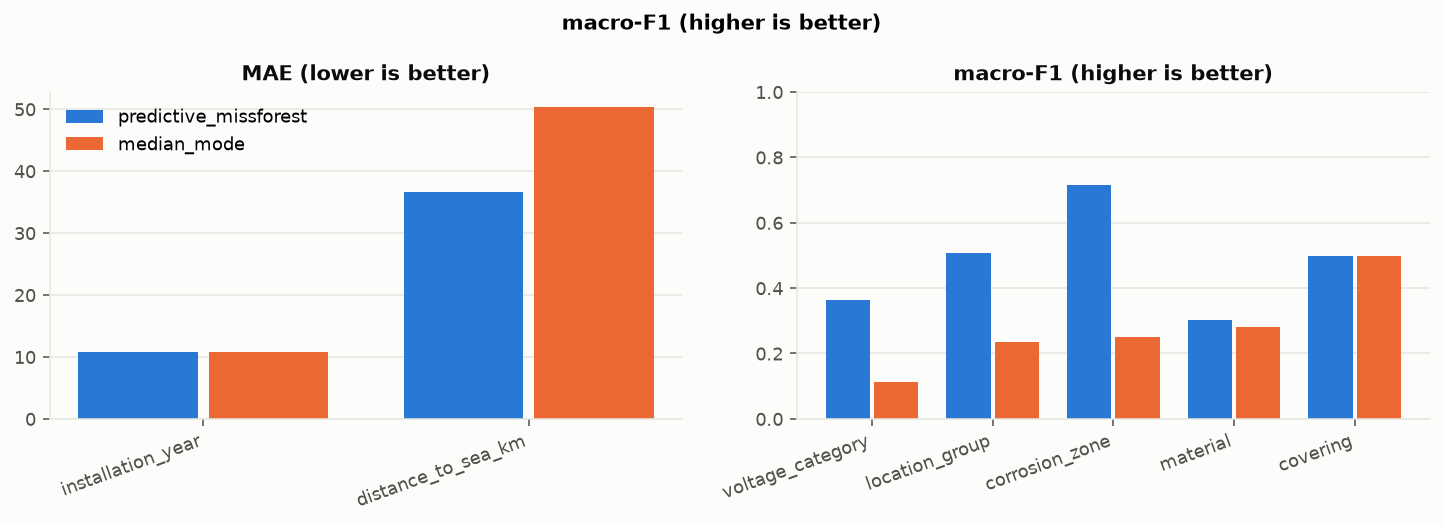

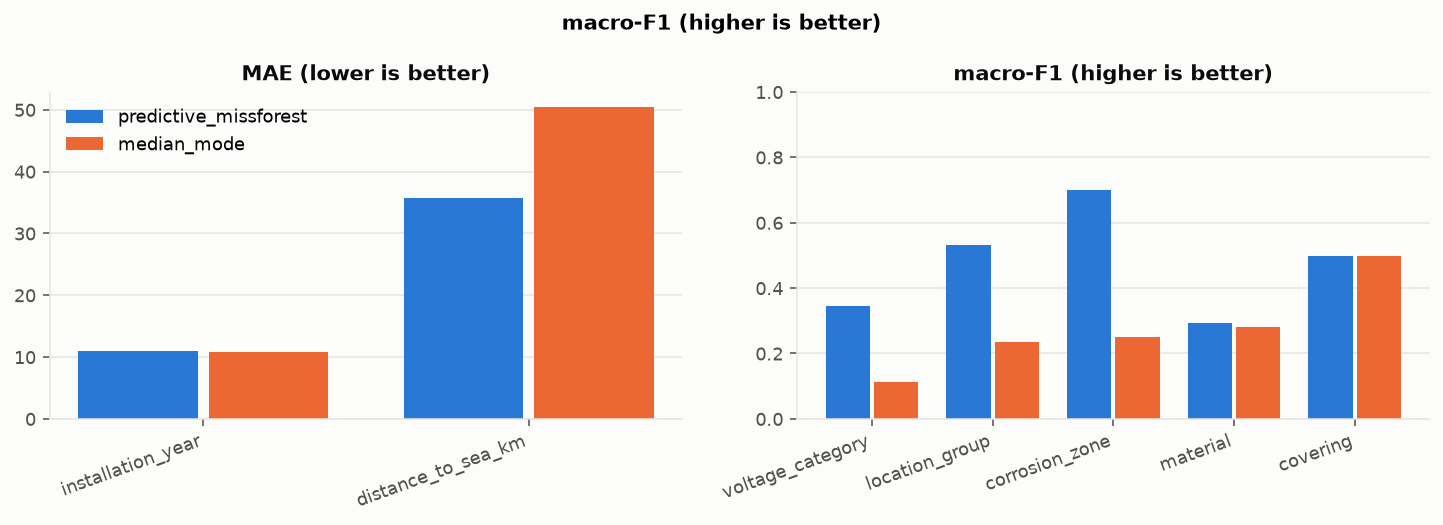

In [ ]:
from src.pipeline import run_evaluate, run_score_saved

evaluation = (run_score_saved(run, settings, TRUTH_CSV) if config.model_execution.mode == 'use_saved'
              else run_evaluate(run, settings, truth_csv=TRUTH_CSV, input_csv=run.cleaned, overrides=OVERRIDES or None))
edir = run.evaluation_dir

print("Truth:", display_path(TRUTH_CSV, PROJECT_ROOT), "| measured input (cleaned):", display_path(run.cleaned, PROJECT_ROOT))
print("Evaluation:", evaluation.get('protocol', evaluation.get('mask_source')), "| partitions:", evaluation.get('partitions', 'saved model, no refit'))
print("Methods and hyperparameters:", evaluation.get('hyperparameters', 'from saved model'))
eval_summary = pd.read_csv(edir / "summary.csv")
display(eval_summary[eval_summary["variable"].isin(schema.primary_targets)])
display(eval_summary)
if (edir / 'per_class.csv').is_file(): display(table(pd.read_csv(edir / 'per_class.csv'), 20))
show_images(sorted((edir / "figures").glob("*.png")))

## 8. Final export and report

The run directory already holds the deliverables; this section renders the single-file HTML report over all of them and lists what to hand over:

- `final_imputed.csv` - completed records in the source column order, integers as integers;
- `cell_provenance.csv` / `provenance_summary.csv` - what was derived, imputed or left unresolved, and by which rule or method;
- `cleaning_log.csv`, `recovery_log.csv`, `derived_fields_log.csv` - every transformation, one row per cell or rule;
- `run_metadata.json` - configuration state and hashes, settings, hyperparameters, per-stage summaries, versions;
- `validation/` and `evaluation/` - the checks and (synthetic) evaluation tables and figures;
- `model.joblib` + `.provenance.json` - the fitted persistable model, if the method supports it;
- `report.html` - all of the above, readable.

The notebook is a readable controller for reusable Python modules, not the only way to execute the system: `oc-pipeline all --asset overhead_conductors --measured <csv> --truth <csv> --out <dir>` produce the same files.

In [ ]:
from src.pipeline import run_report

report_path = run_report(run, settings)
meta = read_metadata(run)
print("Report:", display_path(report_path, PROJECT_ROOT))
print("Run metadata:", display_path(run.metadata, PROJECT_ROOT))
print("Package", meta["package_version"], "| configuration ready:", meta["configuration"]["ready"], "| execution mode:", meta["configuration"]["execution_mode"])
display(list_outputs(RUN_DIR, PROJECT_ROOT))

2026-11-09 17:23:41 INFO report: /Users/zisanaalam/Desktop/GitHub/team19-asset-data/pipeline/outputs/overhead_conductors/run_01/report.html (0.1s)


Report: pipeline/outputs/overhead_conductors/run_01/report.html
Run metadata: pipeline/outputs/overhead_conductors/run_01/run_metadata.json
Package 1.1.0 | configuration ready: False | execution mode: development


,file,size_kb
0,pipeline/outputs/overhead_conductors/run_01/cell_provenance.csv,1955.0
1,pipeline/outputs/overhead_conductors/run_01/cleaned.csv,956.1
2,pipeline/outputs/overhead_conductors/run_01/cleaning_log.csv,0.0
3,pipeline/outputs/overhead_conductors/run_01/convergence.csv,0.3
4,pipeline/outputs/overhead_conductors/run_01/derived_fields_log.csv,0.2
5,pipeline/outputs/overhead_conductors/run_01/diagnostics.csv,2022.9
6,pipeline/outputs/overhead_conductors/run_01/evaluation/evaluation_mask_repeat0.csv,555.5
7,pipeline/outputs/overhead_conductors/run_01/evaluation/figures/transductive_metrics.png,53.9
8,pipeline/outputs/overhead_conductors/run_01/evaluation/figures/unseen_records_metrics.png,53.9
9,pipeline/outputs/overhead_conductors/run_01/evaluation/metrics.csv,4.3
